## Post Updates

Update 11/1/2026: Moved the total correlation metric, decile analysis, and trading strategy here from the original post, which is now [part 1](/posts/asset-class-return-correlations-part-1/). Also added the 2x leveraged funds SSO, MVV, and SAA to the trading strategy, using the same signal as the original IVV, IJH, and IJR strategies.

## Introduction

In [part 1](/posts/asset-class-return-correlations-part-1/), we looked at historical return correlations between asset classes, and saw that the rolling correlations can abruptly increase or decrease in response to market shocks. In this post, we'll build a "total correlation" metric from those rolling correlations, look at future returns based on that metric, and develop a trading strategy that uses correlation as a market timing signal.

 ## Python Imports

In [1]:
import os
import sys
import warnings

from itertools import combinations, count
from pathlib import Path

# Data Handling
import numpy as np
import pandas as pd

# Display
from IPython.display import Markdown, display

# Suppress warnings
warnings.filterwarnings("ignore")

# Add src/ to the path so settings.py and the helper modules can be imported
src_directory = str(Path.cwd().parents[2] / "src")
if src_directory not in sys.path:
    sys.path.append(src_directory)

from settings import config

DATA_DIR = config("DATA_DIR")  # keep only the directories this post uses

## Python Functions

Here are the functions needed for this project:

* [load_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#load_data): Load data from a CSV, Excel, or Pickle file into a pandas DataFrame.
* [pandas_set_decimal_places](/posts/reusable-extensible-python-functions-financial-data-analysis/#pandas_set_decimal_places): Set the number of decimal places displayed for floating-point numbers in pandas.
* [plot_histogram](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_histogram): Plot the histogram of a data set from a DataFrame.
* [plot_scatter](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_scatter): Plot the data from a DataFrame for a specified date range and columns.
* [plot_time_series](/posts/reusable-extensible-python-functions-financial-data-analysis/#plot_time_series): Plot the timeseries data from a DataFrame for a specified date range and columns.
* [summary_stats](/posts/reusable-extensible-python-functions-financial-data-analysis/#summary_stats): Generate summary statistics for a series of returns.
* [yf_pull_data](/posts/reusable-extensible-python-functions-financial-data-analysis/#yf_pull_data): Download daily price data from Yahoo Finance and export it.

In [2]:
from load_data import load_data
from pandas_set_decimal_places import pandas_set_decimal_places
from plot_histogram import plot_histogram
from plot_scatter import plot_scatter
from plot_time_series import plot_time_series
from summary_stats import summary_stats
from yf_pull_data import yf_pull_data

In [3]:
pandas_set_decimal_places(2)
figure_number = count(1)
table_number = count(1)

## Data Overview

The signal in this post comes from the rolling correlations between the following funds:

* Large Cap US Stocks / S&P 500 -- IVV (iShares S&P 500 ETF)
* Mid Cap US Stocks / S&P MidCap 400 -- IJH (iShares S&P MidCap 400 ETF)
* Small Cap US Stocks / S&P SmallCap 600 -- IJR (iShares S&P SmallCap 600 ETF)

We'll also use the following 2x leveraged ETFs, but only in the trading strategy. They do not feed into the signal:

* 2x Large Cap US Stocks / S&P 500 -- SSO (ProShares Ultra S&P500)
* 2x Mid Cap US Stocks / S&P MidCap 400 -- MVV (ProShares Ultra MidCap400)
* 2x Small Cap US Stocks / S&P SmallCap 600 -- SAA (ProShares Ultra SmallCap600)

We'll load the rest of the ETFs from [part 1](/posts/asset-class-return-correlations-part-1/) as well, in order to keep the same sample of days. That sample only includes the days where all of the ETFs have data, so it starts with the inception of GSG in July 2006. Using only IVV, IJH, and IJR would extend the sample back to 2000, and change the deciles and the resulting trades.

For all of these, we will use the adjusted closing price, which accounts for dividends and stock splits.

### Acquire & Load Data

In [4]:
# Create list of tickers to pull data for
us_equity_tickers = ["IVV", "IJH", "IJR", "QQQ", "IWB", "IWD", "IWF", "IWM"]
intl_equity_tickers = ["EFA", "EEM", "IEV"]
equity_tickers = us_equity_tickers + intl_equity_tickers
bond_tickers = ["SHY", "IEF", "TLT", "AGG"]
commodity_tickers = ["GLD", "GSG"]
real_estate_tickers = ["IYR"]

# 2x leveraged funds, used only in the trading strategy. These are kept out of etf_tickers
# so that SAA's later inception date doesn't change the sample used for the correlations.
leveraged_tickers = ["SSO", "MVV", "SAA"]

etf_tickers = (
    us_equity_tickers
    + intl_equity_tickers
    + bond_tickers
    + commodity_tickers
    + real_estate_tickers
)

In [5]:
for ticker in etf_tickers + leveraged_tickers:
    yf_pull_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        adjusted=False,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        excel_export=True,
        pickle_export=True,
        output_confirmation=False,
    )

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

... (11 outputs left out)

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:585: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  dividends.set_index("date", inplace=True)
/home/jared/Cloud_Storage/Dropbox/Websites/jaredszajkowski.github.io/.venv/lib/python3.14/site-packages/yfinance/utils.py:587: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a

In [6]:
fund_data = pd.DataFrame()

for ticker in etf_tickers + leveraged_tickers:
    data = load_data(
        base_directory=DATA_DIR,
        ticker=ticker,
        source="Yahoo_Finance",
        asset_class="Exchange_Traded_Funds",
        timeframe="Daily",
        file_format="pickle",
    )

    # Rename columns to "QQQ_Close", etc.
    data = data.rename(
        columns={
            "Adj Close": f"{ticker}_Adj_Close",
            "Close": f"{ticker}_Close",
            "High": f"{ticker}_High",
            "Low": f"{ticker}_Low",
            "Open": f"{ticker}_Open",
            "Volume": f"{ticker}_Volume",
        }
    )

    # Drop all columns except for the adjusted close price and date index
    data = data[[f"{ticker}_Adj_Close"]]

    # Calculate daily returns and add as new column
    data[f"{ticker}_Daily_Return"] = data[f"{ticker}_Adj_Close"].pct_change()

    # Concatenate the data for this ticker with the main fund_data DataFrame
    fund_data = pd.concat([fund_data, data], axis=1)

display(Markdown(f"Table {next(table_number)}: Fund Data"))
display(fund_data)

Table 1: Fund Data

,IVV_Adj_Close,IVV_Daily_Return,IJH_Adj_Close,IJH_Daily_Return,IJR_Adj_Close,IJR_Daily_Return,QQQ_Adj_Close,QQQ_Daily_Return,IWB_Adj_Close,IWB_Daily_Return,...,GSG_Adj_Close,GSG_Daily_Return,IYR_Adj_Close,IYR_Daily_Return,SSO_Adj_Close,SSO_Daily_Return,MVV_Adj_Close,MVV_Daily_Return,SAA_Adj_Close,SAA_Daily_Return
Date,,,,,,,,,,,,,,,,,,,,,
1999-03-10,NaN,NaN,NaN,NaN,NaN,NaN,42.98,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-11,NaN,NaN,NaN,NaN,NaN,NaN,43.19,0.00,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-12,NaN,NaN,NaN,NaN,NaN,NaN,42.14,-0.02,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-15,NaN,NaN,NaN,NaN,NaN,NaN,43.35,0.03,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1999-03-16,NaN,NaN,NaN,NaN,NaN,NaN,43.72,0.01,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,770.17,0.02,74.59,0.01,142.93,0.01,691.95,0.01,419.20,0.02,...,34.20,-0.04,104.02,0.03,69.62,0.03,84.56,0.01,34.51,0.03
2026-11-05,736.21,-0.04,71.68,-0.04,137.49,-0.04,647.05,-0.06,401.06,-0.04,...,34.53,0.01,102.24,-0.02,63.51,-0.09,77.80,-0.08,31.93,-0.07
2026-11-06,738.68,0.00,72.11,0.01,137.64,0.00,656.10,0.01,402.58,0.00,...,34.46,-0.00,101.62,-0.01,63.85,0.01,78.77,0.01,31.85,-0.00


In [7]:
for ticker in etf_tickers + leveraged_tickers:
    print(f"First date for {ticker}: {fund_data[f'{ticker}_Daily_Return'].first_valid_index()}")

First date for IVV: 2000-05-22 00:00:00
First date for IJH: 2000-05-30 00:00:00
First date for IJR: 2000-05-30 00:00:00
First date for QQQ: 1999-03-11 00:00:00
First date for IWB: 2000-05-22 00:00:00
First date for IWD: 2000-05-30 00:00:00
First date for IWF: 2000-05-30 00:00:00
First date for IWM: 2000-05-30 00:00:00
First date for EFA: 2001-08-28 00:00:00
First date for EEM: 2003-04-15 00:00:00
First date for IEV: 2000-07-31 00:00:00
First date for SHY: 2002-07-31 00:00:00
First date for IEF: 2002-07-31 00:00:00
First date for TLT: 2002-07-31 00:00:00
First date for AGG: 2003-09-30 00:00:00
First date for GLD: 2004-11-19 00:00:00
First date for GSG: 2006-07-24 00:00:00
First date for IYR: 2000-06-20 00:00:00
First date for SSO: 2006-06-22 00:00:00
First date for MVV: 2006-06-22 00:00:00
First date for SAA: 2007-01-26 00:00:00


In [8]:
# Keep only the daily return columns for the ETFs used in the correlations
daily_return_columns = [f"{ticker}_Daily_Return" for ticker in etf_tickers]
fund_data_daily_returns_all = fund_data[daily_return_columns]

# Drop the rows with missing data, which sets the start of the sample
fund_data_daily_returns = fund_data_daily_returns_all.dropna()

print(f"Shape of fund_data_daily_returns_all: {fund_data_daily_returns_all.shape}")
print(f"Shape of fund_data_daily_returns: {fund_data_daily_returns.shape}")
print(f"First date in sample: {fund_data_daily_returns.index[0]}")

Shape of fund_data_daily_returns_all: (6962, 18)
Shape of fund_data_daily_returns: (5108, 18)
First date in sample: 2006-07-24 00:00:00


## Calculate Rolling Correlations

Next, we will calculate the rolling correlations between IVV, IJH, and IJR for the same periods as in part 1.

In [9]:
# Define rolling windows in trading days
rolling_windows = {
    "3d": 3,  # 3 days (~3 trading days)
    "1w": 5,  # 1 week (~5 trading days)
    "2w": 10,  # 2 weeks (~10 trading days)
    "1m": 21,  # 1 month (~21 trading days)
    "3m": 63,  # 3 months (~63 trading days)
    "6m": 126,  # 6 months (~126 trading days)
    "1y": 252,  # 1 year (~252 trading days)
    "5y": 1260,  # 5 years (~1260 trading days)
    "10y": 2520,  # 10 years (~2520 trading days)
}

In [10]:
# Create temp list for tickers
tickers = ["IVV", "IJH", "IJR"]
pairs = list(combinations(tickers, 2))

# Create empty dictionary to store rolling correlation results
rolling_corr_results = {}

# Create empty DataFrame to store rolling correlation results
rolling_corr_results_df = pd.DataFrame()

# Calculate rolling correlations for each pair of tickers and each rolling window
for ticker1, ticker2 in pairs:
    try:
        temp_df = fund_data_daily_returns[
            [f"{ticker1}_Daily_Return", f"{ticker2}_Daily_Return"]
        ].dropna()
    except Exception as e:
        print(f"Error creating temp_df for {ticker1} and {ticker2}: {e}")
        continue

    for window_name, window_size in rolling_windows.items():
        try:
            rolling_corr = (
                temp_df[f"{ticker1}_Daily_Return"]
                .rolling(window=window_size)
                .corr(temp_df[f"{ticker2}_Daily_Return"])
            )

            rolling_corr_results[
                f"{ticker1}_{ticker2}_{window_name}"
            ] = rolling_corr
            rolling_corr_results_df = pd.concat(
                [
                    rolling_corr_results_df,
                    rolling_corr.to_frame(name=f"{ticker1}_{ticker2}_{window_name}"),
                ],
                axis=1,
            )

        except Exception as e:
            print(
                f"Error calculating rolling correlation for {ticker1} and {ticker2} with window {window_name}: {e}"
            )

display(Markdown(f"Table {next(table_number)}: Rolling Correlations"))
display(rolling_corr_results_df)

Table 2: Rolling Correlations

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IVV_IJR_10y,IJH_IJR_3d,IJH_IJR_1w,IJH_IJR_2w,IJH_IJR_1m,IJH_IJR_3m,IJH_IJR_6m,IJH_IJR_1y,IJH_IJR_5y,IJH_IJR_10y
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,1.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.98,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,-0.23,0.58,0.67,0.64,0.70,0.75,0.80,0.88,0.90,0.40,...,0.83,0.80,0.92,0.76,0.87,0.89,0.91,0.93,0.97,0.96
2026-11-05,0.99,0.93,0.90,0.88,0.80,0.79,0.81,0.88,0.90,0.99,...,0.83,0.97,0.97,0.97,0.93,0.93,0.92,0.94,0.97,0.96
2026-11-06,0.98,0.93,0.90,0.89,0.80,0.79,0.81,0.88,0.90,1.00,...,0.83,0.97,0.97,0.97,0.93,0.92,0.92,0.94,0.97,0.96


## Total Correlation Metric

As we saw in [part 1](/posts/asset-class-return-correlations-part-1/), there are periods of time when the correlations abruptly increase or decrease as a response to some kind of market shock or event.

As an attempt to find some kind of signal, let's simply add the correlations together to get a "total correlation" metric, and look at the distribution. Note that we normalize the correlations to account for the number of correlations being summed by dividing the total by the number of correlations, to keep the values between -1 and 1.

In [11]:
# Calculate total rolling correlation for each window
for window, days in rolling_windows.items():
    rolling_corr_results_df[f"total_rolling_correlation_{window}"] = rolling_corr_results_df[[col for col in rolling_corr_results_df.columns if col.endswith(f"_{window}")]].sum(axis=1) / len([col for col in rolling_corr_results_df.columns if col.endswith(f"_{window}")])

# Reset any 0.00 values to NaN
rolling_corr_results_df.replace(0.00, np.nan, inplace=True)

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_IJR_10y,total_rolling_correlation_3d,total_rolling_correlation_1w,total_rolling_correlation_2w,total_rolling_correlation_1m,total_rolling_correlation_3m,total_rolling_correlation_6m,total_rolling_correlation_1y,total_rolling_correlation_5y,total_rolling_correlation_10y
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,0.98,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.99,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,-0.23,0.58,0.67,0.64,0.70,0.75,0.80,0.88,0.90,0.40,...,0.96,0.32,0.70,0.64,0.68,0.73,0.77,0.82,0.89,0.90
2026-11-05,0.99,0.93,0.90,0.88,0.80,0.79,0.81,0.88,0.90,0.99,...,0.96,0.98,0.95,0.92,0.87,0.82,0.81,0.83,0.89,0.90
2026-11-06,0.98,0.93,0.90,0.89,0.80,0.79,0.81,0.88,0.90,1.00,...,0.96,0.98,0.95,0.91,0.87,0.82,0.81,0.83,0.89,0.90


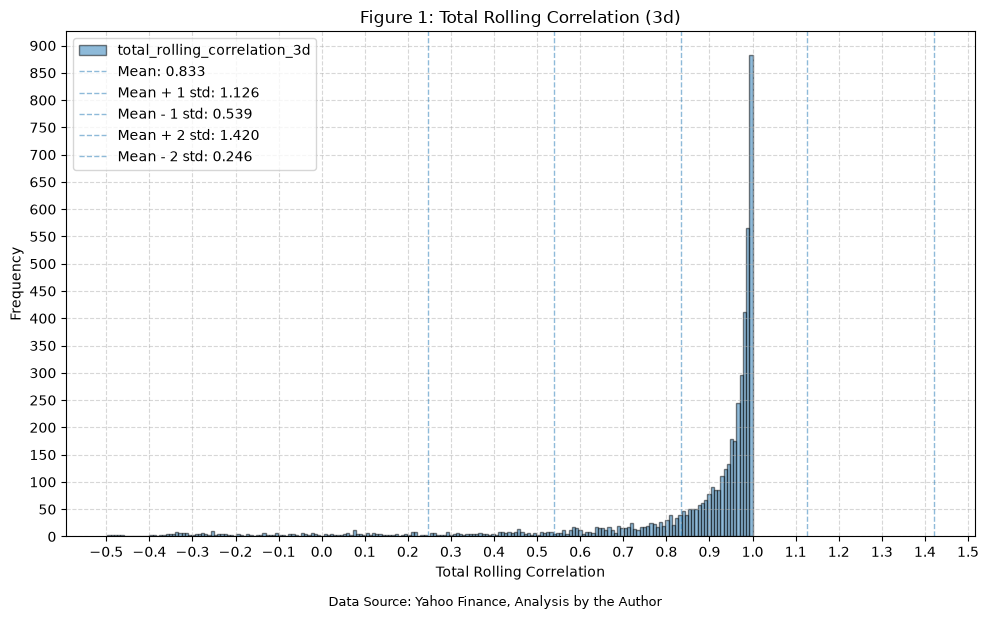

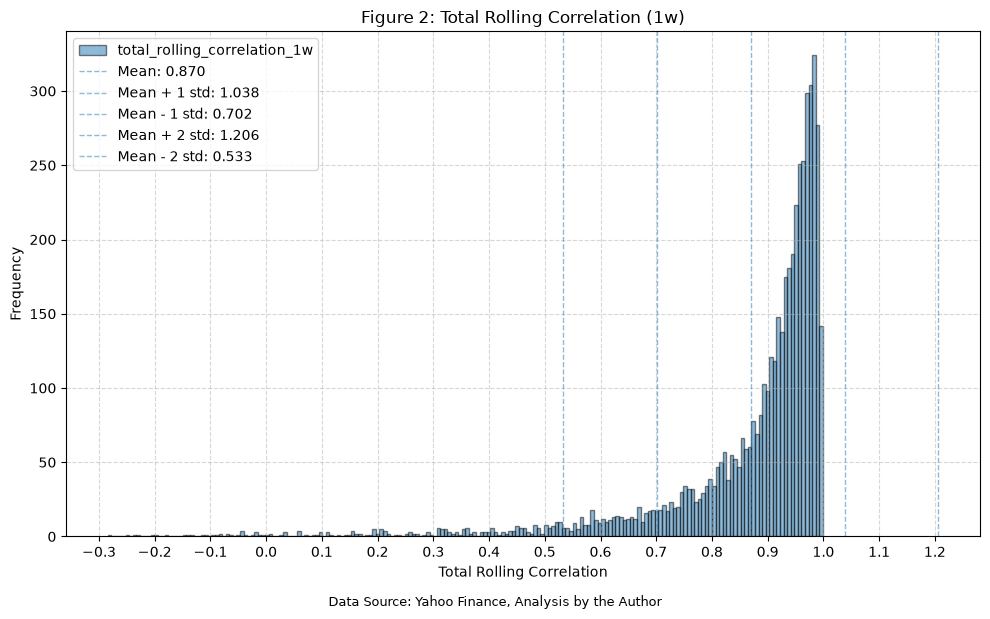

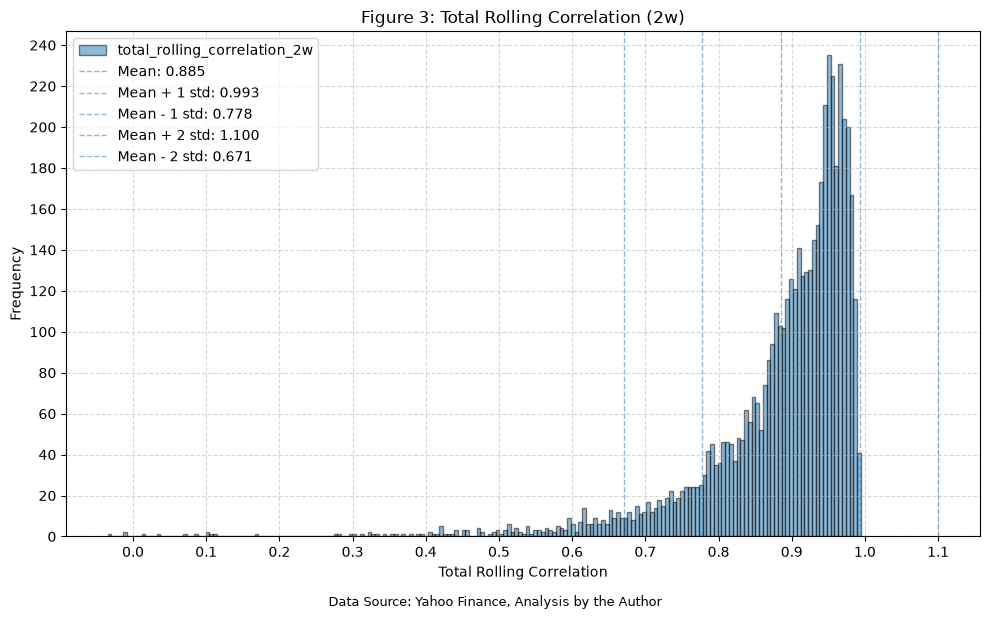

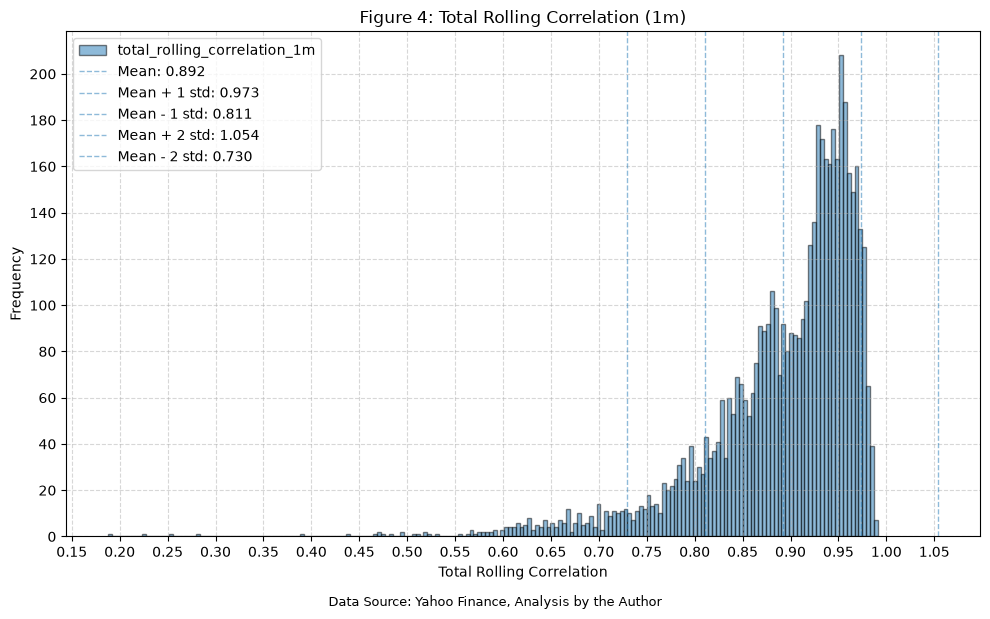

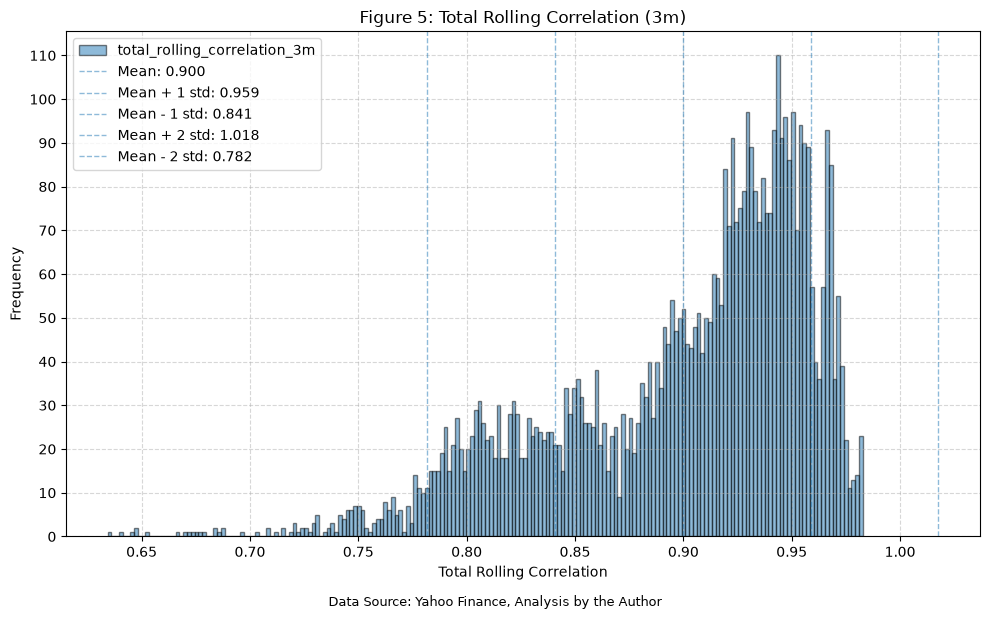

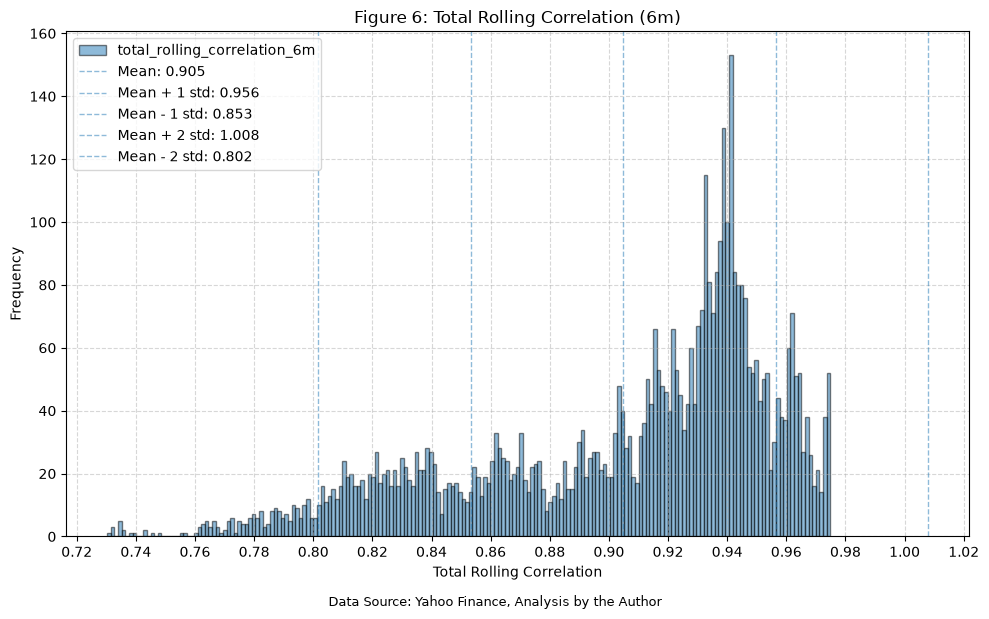

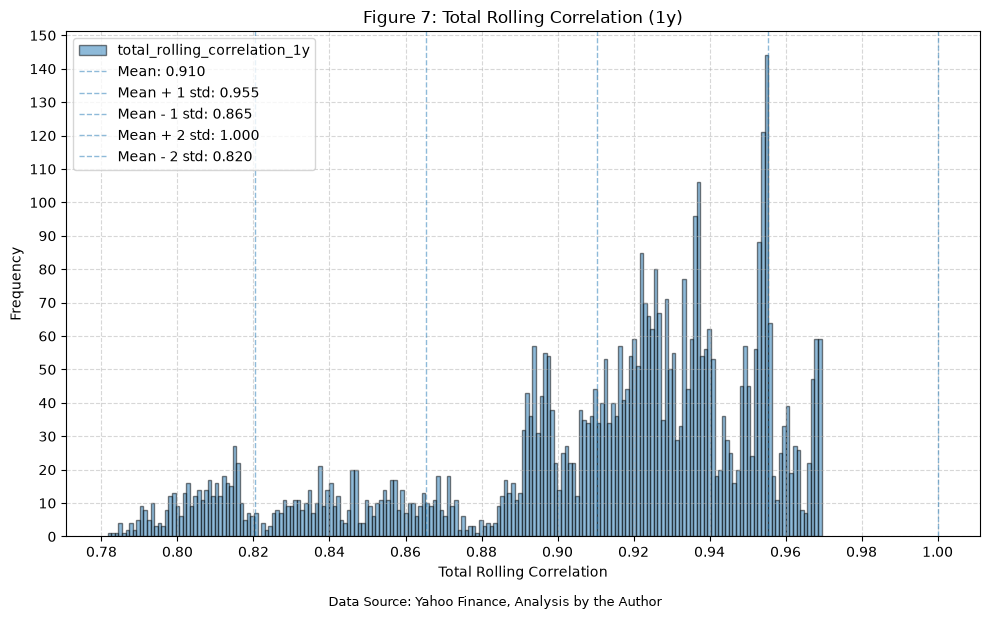

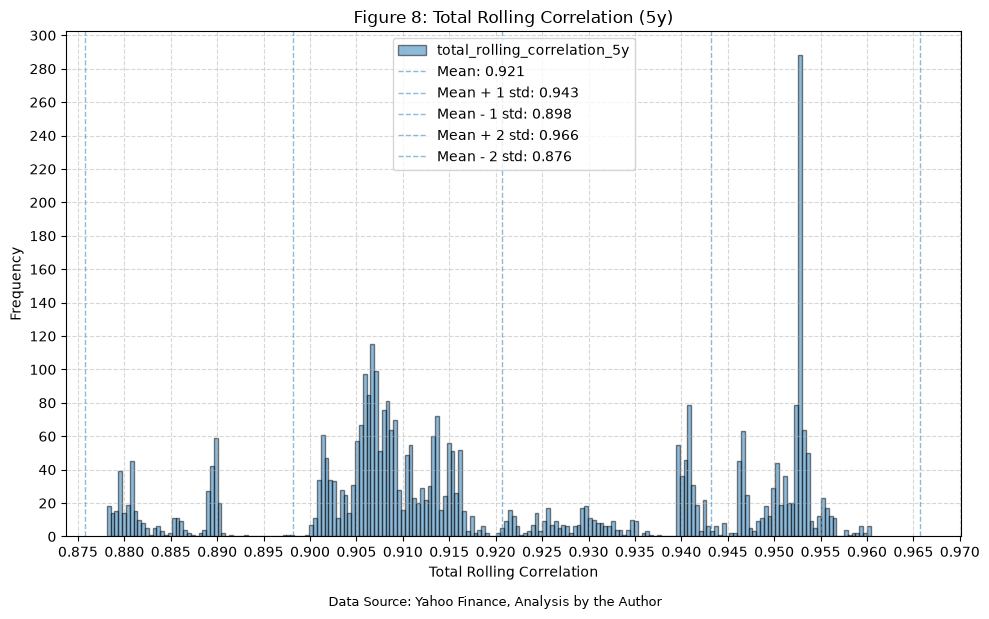

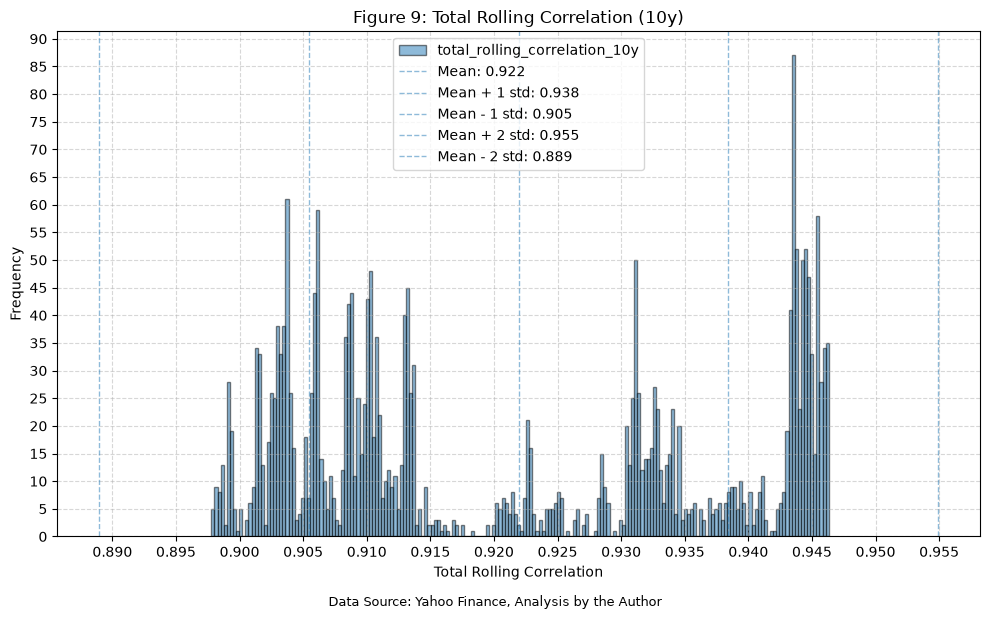

In [12]:
for window in rolling_windows.keys():
    plot_histogram(
        df=rolling_corr_results_df[[f"total_rolling_correlation_{window}"]].dropna(),
        plot_columns=[f"total_rolling_correlation_{window}"],
        title=f"Figure {next(figure_number)}: Total Rolling Correlation ({window})",
        x_label="Total Rolling Correlation",
        x_tick_spacing="Auto",
        x_tick_rotation=0,
        y_label="Frequency",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

Alright, so the distributions for 1w, 2w, and 1m look interesting. For each of those windows, let's look at the different deciles of the rolling correlations, and what that implies for future returns.

## Future Returns Based On Total Rolling Correlation

First, we need to define the forward return windows that we want to look at.

In [13]:
# Define rolling windows in trading days
return_windows = {
    "1d": 1,  # 1 day (~1 trading day)
    "3d": 3,  # 3 days (~3 trading days)
    "1w": 5,  # 1 week (~5 trading days)
    "2w": 10,  # 2 weeks (~10 trading days)
    "1m": 21,  # 1 month (~21 trading days)
    "2m": 42,  # 2 months (~42 trading days)
    "3m": 63,  # 3 months (~63 trading days)
}

Then, we'll merge in the returns and create the forward returns for each of the funds.

In [14]:
# Merge daily returns in for the ETFs
total_rolling_corr_with_returns = rolling_corr_results_df.merge(
    fund_data_daily_returns_all[
        [f"{ft}_Daily_Return" for ft in tickers]
    ].dropna(),
    left_index=True,
    right_index=True,
    how="left",
)

# Calculate compounded rolling returns (CRR), and then shift to create forward returns
for rw in return_windows.keys():
    for ft in tickers:
        total_rolling_corr_with_returns[f"{ft}_Daily_Return_{rw}_CRR"] = (
            total_rolling_corr_with_returns[f"{ft}_Daily_Return"]
            .rolling(window=return_windows[rw])
            .apply(lambda x: (1 + x).prod() - 1, raw=True)
        )
        total_rolling_corr_with_returns[f"{ft}_Daily_Return_fwd_{rw}_CRR"] = total_rolling_corr_with_returns[
            f"{ft}_Daily_Return_{rw}_CRR"
        ].shift(-return_windows[rw])

display(Markdown(f"Table {next(table_number)}: Total Rolling Correlations With Forward Returns"))
display(total_rolling_corr_with_returns)

Table 3: Total Rolling Correlations With Forward Returns

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_Daily_Return_2m_CRR,IJH_Daily_Return_fwd_2m_CRR,IJR_Daily_Return_2m_CRR,IJR_Daily_Return_fwd_2m_CRR,IVV_Daily_Return_3m_CRR,IVV_Daily_Return_fwd_3m_CRR,IJH_Daily_Return_3m_CRR,IJH_Daily_Return_fwd_3m_CRR,IJR_Daily_Return_3m_CRR,IJR_Daily_Return_fwd_3m_CRR
Date,,,,,,,,,,,,,,,,,,,,,
2006-07-24,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.03,NaN,0.04,NaN,0.09,NaN,0.07,NaN,0.08
2006-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,0.01,NaN,0.02,NaN,0.09,NaN,0.07,NaN,0.08
2006-07-26,0.97,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,NaN,0.02,NaN,0.04,NaN,0.09,NaN,0.07,NaN,0.09
2006-07-27,0.99,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.93,...,NaN,0.04,NaN,0.06,NaN,0.10,NaN,0.09,NaN,0.11
2006-07-28,1.00,0.96,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.99,...,NaN,0.03,NaN,0.05,NaN,0.09,NaN,0.08,NaN,0.10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,-0.23,0.58,0.67,0.64,0.70,0.75,0.80,0.88,0.90,0.40,...,-0.01,NaN,-0.01,NaN,0.00,NaN,-0.03,NaN,-0.03,NaN
2026-11-05,0.99,0.93,0.90,0.88,0.80,0.79,0.81,0.88,0.90,0.99,...,-0.05,NaN,-0.04,NaN,-0.05,NaN,-0.08,NaN,-0.07,NaN
2026-11-06,0.98,0.93,0.90,0.89,0.80,0.79,0.81,0.88,0.90,1.00,...,-0.03,NaN,-0.03,NaN,-0.05,NaN,-0.07,NaN,-0.07,NaN


### Summary By Decile

Before looking at the individual plots, here is a summary of the forward returns for each decile of total rolling correlation compared with the baseline (all days). Values are in percent.

In [15]:
analysis_windows = ["1w", "2w", "1m"]
decile_labels = [f"D{i}" for i in range(1, 11)]

decile_summary = {}

for window in analysis_windows:
    col = f"total_rolling_correlation_{window}"
    df = total_rolling_corr_with_returns.dropna(subset=[col])

    # Assign each day to a correlation decile and record each decile's range
    bucket = pd.qcut(df[col], 10, labels=decile_labels)
    ranges = df[col].groupby(bucket, observed=True).agg(["min", "max"])
    row_labels = ["Baseline (all days)"] + [
        f"{d} ({ranges.loc[d, 'min']:.2f} to {ranges.loc[d, 'max']:.2f})" for d in decile_labels
    ]

    pct_positive = {}
    mean_return = {}
    for rw in return_windows.keys():
        for ft in tickers:
            fwd = df[f"{ft}_Daily_Return_fwd_{rw}_CRR"]
            valid = fwd.notna()
            fwd, b = fwd[valid], bucket[valid]
            pct_positive[(rw, ft)] = [(fwd > 0).mean() * 100] + list(fwd.gt(0).groupby(b, observed=True).mean() * 100)
            mean_return[(rw, ft)] = [fwd.mean() * 100] + list(fwd.groupby(b, observed=True).mean() * 100)

    decile_summary[window] = {
        "pct_positive": pd.DataFrame(pct_positive, index=row_labels),
        "mean_return": pd.DataFrame(mean_return, index=row_labels),
    }

In [16]:
for window in analysis_windows:
    display(Markdown(f"Table {next(table_number)}: Percentage of Positive Future Returns by {window} Total Rolling Correlation Decile"))
    display(decile_summary[window]["pct_positive"])
    display(Markdown(f"Table {next(table_number)}: Mean Future Return (%) by {window} Total Rolling Correlation Decile"))
    display(decile_summary[window]["mean_return"])

Table 4: Percentage of Positive Future Returns by 1w Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 54.83 53.69 52.32 58.71 55.42 53.99 60.09 56.93 55.05   
D1 (-0.28 to 0.68)  54.01 48.14 47.16 57.34 50.29 47.36 60.08 54.40 50.10   
D2 (0.68 to 0.81)   56.08 54.90 51.57 57.45 54.90 50.59 57.37 54.62 50.69   
D3 (0.81 to 0.87)   54.71 49.41 50.78 57.45 53.53 52.75 60.20 54.90 54.12   
D4 (0.87 to 0.91)   56.16 59.30 58.32 62.43 57.14 56.75 63.41 60.67 60.08   
D5 (0.91 to 0.93)   59.22 58.24 55.69 60.98 57.65 56.86 60.39 55.69 53.33   
D6 (0.93 to 0.95)   49.61 49.80 48.63 54.42 52.06 51.47 56.50 54.72 53.94   
D7 (0.95 to 0.96)   54.21 54.40 53.42 61.45 60.27 59.10 63.60 60.47 58.12   
D8 (0.96 to 0.97)   53.14 52.75 50.78 58.55 55.40 53.63 59.33 58.74 55.01   
D9 (0.97 to 0.98)   55.99 56.58 54.22 59.14 57.17 55.60 59.33 57.56 56.78   
D10 (0.98 to 1.00)  55.19 53.42 52.64 57.93 55.77 55.77 60.67 57.53 58.32   

                       2w  ...          1m                2m              \
                      IVV  ...   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 63.78  ... 57.36 67.52 62.35 60.91 71.59 67.01 65.57   
D1 (-0.28 to 0.68)  66.93  ... 56.50 68.39 56.86 54.47 73.65 64.67 62.08   
D2 (0.68 to 0.81)   64.10  ... 53.45 67.19 59.68 57.91 74.00 67.80 66.00   
D3 (0.81 to 0.87)   64.71  ... 56.08 67.39 60.71 58.35 71.94 65.42 62.25   
D4 (0.87 to 0.91)   59.49  ... 55.19 67.58 60.90 58.74 69.09 65.16 66.14   
D5 (0.91 to 0.93)   66.27  ... 57.25 66.60 63.85 62.08 68.91 64.36 63.17   
D6 (0.93 to 0.95)   57.48  ... 55.31 62.52 61.34 59.96 66.60 63.64 63.04   
D7 (0.95 to 0.96)   69.08  ... 58.90 69.28 64.38 63.41 71.26 67.91 63.58   
D8 (0.96 to 0.97)   62.08  ... 57.96 68.57 65.42 64.64 73.28 69.16 68.57   
D9 (0.97 to 0.98)   65.62  ... 61.49 67.19 63.46 64.24 73.23 69.69 70.28   
D10 (0.98 to 1.00)  62.04  ... 61.45 70.45 66.73 65.17 73.97 72.21 70.45   

                       3m              
                      IVV   IJH   IJR  
Baseline (all days) 73.83 69.37 66.59  
D1 (-0.28 to 0.68)  78.16 68.74 64.53  
D2 (0.68 to 0.81)   76.83 71.75 68.29  
D3 (0.81 to 0.87)   76.00 70.80 68.20  
D4 (0.87 to 0.91)   75.25 68.32 66.93  
D5 (0.91 to 0.93)   70.63 63.89 62.90  
D6 (0.93 to 0.95)   66.73 63.56 60.40  
D7 (0.95 to 0.96)   72.44 70.67 67.91  
D8 (0.96 to 0.97)   72.10 71.71 68.17  
D9 (0.97 to 0.98)   72.64 68.70 66.54  
D10 (0.98 to 1.00)  77.69 75.54 72.02  

[11 rows x 21 columns]

Table 5: Mean Future Return (%) by 1w Total Rolling Correlation Decile

1d                3d               1w              2w  \
                      IVV   IJH   IJR   IVV   IJH   IJR  IVV  IJH   IJR  IVV   
Baseline (all days)  0.05  0.05  0.05  0.14  0.14  0.14 0.24 0.23  0.23 0.48   
D1 (-0.28 to 0.68)   0.07  0.05  0.04  0.12  0.05  0.04 0.25 0.24  0.26 0.53   
D2 (0.68 to 0.81)    0.05  0.03  0.02  0.11  0.09  0.05 0.13 0.03 -0.03 0.38   
D3 (0.81 to 0.87)   -0.00 -0.03 -0.02  0.10  0.03  0.03 0.14 0.05  0.06 0.38   
D4 (0.87 to 0.91)    0.12  0.11  0.09  0.27  0.26  0.24 0.33 0.31  0.31 0.34   
D5 (0.91 to 0.93)    0.13  0.16  0.16  0.24  0.27  0.25 0.31 0.34  0.28 0.62   
D6 (0.93 to 0.95)   -0.07 -0.10 -0.10 -0.03 -0.06 -0.03 0.08 0.11  0.13 0.10   
D7 (0.95 to 0.96)    0.04  0.06  0.07  0.35  0.38  0.38 0.48 0.48  0.48 0.87   
D8 (0.96 to 0.97)    0.08  0.11  0.12  0.10  0.17  0.15 0.15 0.21  0.22 0.30   
D9 (0.97 to 0.98)    0.04  0.05  0.06  0.08  0.09  0.14 0.28 0.31  0.34 0.77   
D10 (0.98 to 1.00)   0.04  0.04  0.04  0.12  0.11  0.12 0.25 0.20  0.23 0.50   

                     ...        1m             2m             3m            
                     ...  IJR  IVV  IJH  IJR  IVV  IJH  IJR  IVV  IJH  IJR  
Baseline (all days)  ... 0.45 1.01 0.95 0.95 2.01 1.90 1.88 3.00 2.84 2.81  
D1 (-0.28 to 0.68)   ... 0.70 0.95 0.70 0.82 1.90 1.45 1.39 2.95 1.94 1.52  
D2 (0.68 to 0.81)    ... 0.15 0.85 0.43 0.35 1.82 1.40 1.40 2.93 2.34 2.37  
D3 (0.81 to 0.87)    ... 0.22 0.85 0.68 0.66 1.77 1.36 1.22 3.13 2.67 2.68  
D4 (0.87 to 0.91)    ... 0.35 0.68 0.59 0.63 1.70 1.53 1.68 2.63 2.36 2.47  
D5 (0.91 to 0.93)    ... 0.54 1.07 1.07 1.02 1.70 1.49 1.36 2.26 2.03 1.96  
D6 (0.93 to 0.95)    ... 0.09 0.55 0.72 0.71 0.85 0.78 0.81 1.69 1.74 1.81  
D7 (0.95 to 0.96)    ... 0.79 1.38 1.42 1.37 2.11 2.21 2.14 3.20 3.41 3.45  
D8 (0.96 to 0.97)    ... 0.28 0.92 0.97 0.93 2.33 2.47 2.45 3.30 3.38 3.33  
D9 (0.97 to 0.98)    ... 0.83 1.22 1.29 1.30 2.50 2.60 2.64 3.36 3.41 3.36  
D10 (0.98 to 1.00)   ... 0.57 1.60 1.68 1.68 3.43 3.65 3.67 4.56 5.07 5.09  

[11 rows x 21 columns]

Table 6: Percentage of Positive Future Returns by 2w Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 54.85 53.71 52.31 58.71 55.42 53.98 60.09 56.97 55.08   
D1 (-0.03 to 0.76)  55.29 48.43 47.65 60.20 48.63 47.84 63.65 53.63 50.69   
D2 (0.76 to 0.83)   54.71 55.49 54.71 58.43 57.25 53.33 60.39 56.86 53.92   
D3 (0.83 to 0.87)   51.57 53.14 52.16 54.51 51.96 50.98 54.90 53.14 52.35   
D4 (0.87 to 0.90)   57.25 55.88 54.31 57.65 53.92 52.16 58.04 55.88 53.92   
D5 (0.90 to 0.92)   54.71 56.67 52.35 62.08 60.71 56.97 62.40 63.58 56.89   
D6 (0.92 to 0.94)   56.30 53.74 53.15 58.19 56.61 54.04 58.97 55.62 52.66   
D7 (0.94 to 0.95)   56.08 54.12 49.80 59.80 55.88 55.10 57.25 54.51 55.69   
D8 (0.95 to 0.96)   51.96 48.82 50.78 57.25 54.12 55.10 59.22 55.88 54.12   
D9 (0.96 to 0.97)   56.27 54.51 53.14 64.31 60.39 60.39 66.47 63.92 63.14   
D10 (0.97 to 0.99)  54.31 56.27 55.10 54.71 54.71 53.92 59.61 56.67 57.45   

                       2w  ...          1m                2m              \
                      IVV  ...   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 63.78  ... 57.36 67.49 62.31 60.87 71.56 66.98 65.53   
D1 (-0.03 to 0.76)  68.85  ... 55.36 72.26 59.08 56.29 75.50 63.45 63.65   
D2 (0.76 to 0.83)   66.47  ... 52.55 70.72 60.36 58.37 74.44 66.13 62.47   
D3 (0.83 to 0.87)   57.06  ... 50.98 64.31 59.41 57.84 71.49 68.12 65.94   
D4 (0.87 to 0.90)   63.92  ... 57.06 63.73 58.04 57.45 68.24 65.88 61.74   
D5 (0.90 to 0.92)   66.54  ... 59.45 70.87 66.93 64.76 74.95 69.43 67.65   
D6 (0.92 to 0.94)   61.54  ... 56.02 62.33 60.36 58.19 67.65 63.91 63.91   
D7 (0.94 to 0.95)   57.65  ... 56.27 62.35 59.41 58.43 64.31 59.02 58.43   
D8 (0.95 to 0.96)   63.14  ... 58.24 61.57 61.96 60.59 66.47 63.53 61.76   
D9 (0.96 to 0.97)   66.67  ... 62.75 72.35 66.47 64.12 73.92 71.18 70.78   
D10 (0.97 to 0.99)  66.08  ... 64.90 74.51 70.98 72.55 78.82 79.02 78.82   

                       3m              
                      IVV   IJH   IJR  
Baseline (all days) 73.81 69.34 66.56  
D1 (-0.03 to 0.76)  79.07 67.20 65.19  
D2 (0.76 to 0.83)   78.42 72.61 65.77  
D3 (0.83 to 0.87)   76.91 72.29 68.88  
D4 (0.87 to 0.90)   71.49 64.55 64.36  
D5 (0.90 to 0.92)   74.95 68.64 66.07  
D6 (0.92 to 0.94)   70.41 65.88 65.29  
D7 (0.94 to 0.95)   63.33 61.96 59.61  
D8 (0.95 to 0.96)   65.69 65.29 61.57  
D9 (0.96 to 0.97)   75.69 73.92 69.41  
D10 (0.97 to 0.99)  82.55 81.18 79.41  

[11 rows x 21 columns]

... (2 outputs left out)

Table 8: Percentage of Positive Future Returns by 1m Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 54.85 53.73 52.33 58.70 55.46 54.00 60.10 56.97 55.09   
D1 (0.19 to 0.79)   55.80 51.87 50.29 58.35 52.65 49.12 57.87 52.36 50.20   
D2 (0.79 to 0.84)   55.01 51.87 51.28 59.53 50.88 49.12 60.90 51.67 50.29   
D3 (0.84 to 0.87)   55.40 55.21 52.06 58.86 53.94 50.59 61.34 56.21 50.89   
D4 (0.87 to 0.89)   53.74 54.33 50.98 58.27 58.07 53.54 59.65 61.02 57.68   
D5 (0.89 to 0.92)   56.30 55.51 55.12 60.55 57.99 58.38 59.17 57.79 56.80   
D6 (0.92 to 0.93)   53.24 52.06 51.28 58.55 57.56 55.60 60.12 60.12 59.33   
D7 (0.93 to 0.94)   55.51 53.74 52.36 54.33 50.79 50.79 55.51 52.17 52.56   
D8 (0.94 to 0.95)   55.99 53.83 52.06 58.94 56.39 58.74 64.83 60.12 57.37   
D9 (0.95 to 0.97)   54.03 55.60 54.42 62.48 59.14 56.19 60.51 58.35 56.39   
D10 (0.97 to 0.99)  53.44 53.24 53.44 57.17 57.17 57.96 61.10 59.92 59.33   

                       2w  ...          1m                2m              \
                      IVV  ...   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days) 63.71  ... 57.27 67.42 62.25 60.79 71.50 66.90 65.46   
D1 (0.19 to 0.79)   62.43  ... 54.47 67.61 59.11 55.26 73.93 62.12 59.47   
D2 (0.79 to 0.84)   66.60  ... 50.88 64.69 55.42 54.24 71.69 65.17 60.49   
D3 (0.84 to 0.87)   65.29  ... 51.28 72.78 61.14 58.58 78.22 68.91 62.97   
D4 (0.87 to 0.89)   60.63  ... 56.69 69.49 62.20 59.84 72.64 70.47 69.29   
D5 (0.89 to 0.92)   64.69  ... 57.40 68.05 64.10 60.75 70.81 64.50 64.30   
D6 (0.92 to 0.93)   56.97  ... 57.37 60.90 60.12 61.30 58.94 54.03 52.46   
D7 (0.93 to 0.94)   59.25  ... 55.71 64.17 59.65 58.66 62.80 62.01 62.01   
D8 (0.94 to 0.95)   64.05  ... 60.12 64.64 64.24 63.26 71.32 70.14 71.91   
D9 (0.95 to 0.97)   69.74  ... 62.67 68.96 66.80 65.62 74.66 73.48 72.89   
D10 (0.97 to 0.99)  67.39  ... 66.01 72.89 69.55 70.14 80.16 78.00 78.39   

                       3m              
                      IVV   IJH   IJR  
Baseline (all days) 73.75 69.27 66.49  
D1 (0.19 to 0.79)   74.85 60.12 57.26  
D2 (0.79 to 0.84)   80.86 74.69 70.37  
D3 (0.84 to 0.87)   74.14 67.07 66.06  
D4 (0.87 to 0.89)   80.75 71.63 71.63  
D5 (0.89 to 0.92)   71.99 68.44 66.07  
D6 (0.92 to 0.93)   58.94 54.81 51.47  
D7 (0.93 to 0.94)   64.96 65.16 57.87  
D8 (0.94 to 0.95)   74.07 73.48 71.12  
D9 (0.95 to 0.97)   73.67 76.42 72.89  
D10 (0.97 to 0.99)  83.69 80.75 79.96  

[11 rows x 21 columns]

Table 9: Mean Future Return (%) by 1m Total Rolling Correlation Decile

1d                3d                1w              \
                      IVV   IJH   IJR   IVV   IJH   IJR   IVV   IJH   IJR   
Baseline (all days)  0.05  0.05  0.05  0.14  0.14  0.14  0.24  0.23  0.23   
D1 (0.19 to 0.79)    0.02 -0.01  0.00  0.07  0.04  0.08  0.13  0.08  0.15   
D2 (0.79 to 0.84)    0.06  0.04  0.05  0.15  0.04  0.04  0.28  0.12  0.10   
D3 (0.84 to 0.87)    0.07  0.06  0.04  0.19  0.16  0.09  0.30  0.18  0.09   
D4 (0.87 to 0.89)    0.02  0.05  0.04  0.16  0.22  0.20  0.25  0.34  0.34   
D5 (0.89 to 0.92)    0.10  0.12  0.13  0.18  0.22  0.27  0.24  0.31  0.40   
D6 (0.92 to 0.93)    0.02  0.02  0.03  0.11  0.16  0.16  0.13  0.23  0.23   
D7 (0.93 to 0.94)   -0.01 -0.01 -0.01 -0.17 -0.20 -0.18 -0.05 -0.11 -0.11   
D8 (0.94 to 0.95)    0.03  0.02  0.02  0.18  0.19  0.19  0.28  0.29  0.28   
D9 (0.95 to 0.97)    0.12  0.10  0.10  0.26  0.22  0.18  0.25  0.19  0.13   
D10 (0.97 to 0.99)   0.05  0.07  0.07  0.29  0.34  0.35  0.58  0.66  0.67   

                      2w  ...        1m              2m               3m       \
                     IVV  ...  IJR  IVV  IJH  IJR   IVV   IJH   IJR  IVV  IJH   
Baseline (all days) 0.48  ... 0.45 1.00 0.95 0.94  2.00  1.89  1.87 2.99 2.83   
D1 (0.19 to 0.79)   0.35  ... 0.37 0.80 0.50 0.60  1.24  0.16 -0.07 2.48 0.57   
D2 (0.79 to 0.84)   0.53  ... 0.27 0.64 0.33 0.36  1.79  1.10  1.09 3.39 2.58   
D3 (0.84 to 0.87)   0.60  ... 0.19 1.30 0.96 0.77  2.38  1.82  1.79 2.90 2.08   
D4 (0.87 to 0.89)   0.35  ... 0.49 1.22 1.20 1.26  2.44  2.30  2.49 3.41 3.53   
D5 (0.89 to 0.92)   0.54  ... 0.74 1.08 1.12 1.23  1.62  1.51  1.69 2.34 2.37   
D6 (0.92 to 0.93)   0.15  ... 0.35 0.15 0.34 0.33 -0.46 -0.39 -0.58 0.13 0.23   
D7 (0.93 to 0.94)   0.12  ... 0.04 0.47 0.28 0.38  0.77  0.84  0.75 1.28 1.49   
D8 (0.94 to 0.95)   0.35  ... 0.39 0.56 0.64 0.59  2.23  2.60  2.69 3.28 3.75   
D9 (0.95 to 0.97)   0.65  ... 0.45 1.21 1.30 1.20  2.79  3.21  3.22 3.78 4.25   
D10 (0.97 to 0.99)  1.12  ... 1.23 2.60 2.82 2.71  5.18  5.65  5.49 6.87 7.32   

                           
                      IJR  
Baseline (all days)  2.79  
D1 (0.19 to 0.79)   -0.16  
D2 (0.79 to 0.84)    2.73  
D3 (0.84 to 0.87)    2.35  
D4 (0.87 to 0.89)    4.05  
D5 (0.89 to 0.92)    2.75  
D6 (0.92 to 0.93)   -0.10  
D7 (0.93 to 0.94)    1.30  
D8 (0.94 to 0.95)    3.71  
D9 (0.95 to 0.97)    4.21  
D10 (0.97 to 0.99)   6.95  

[11 rows x 21 columns]

### Plots By Decile

Now the plots to illustrate the tables above:

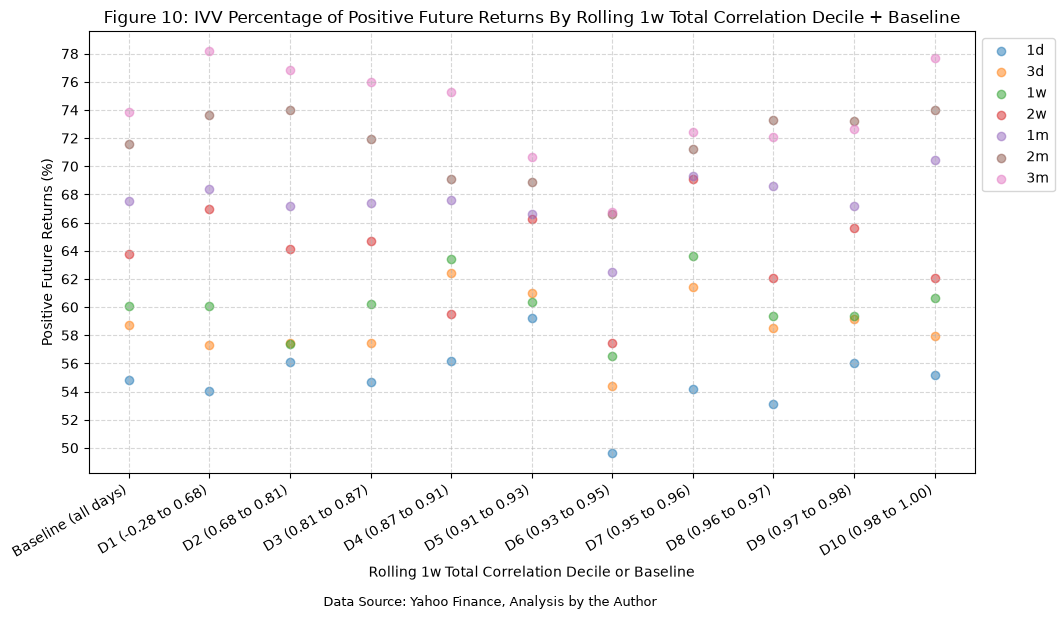

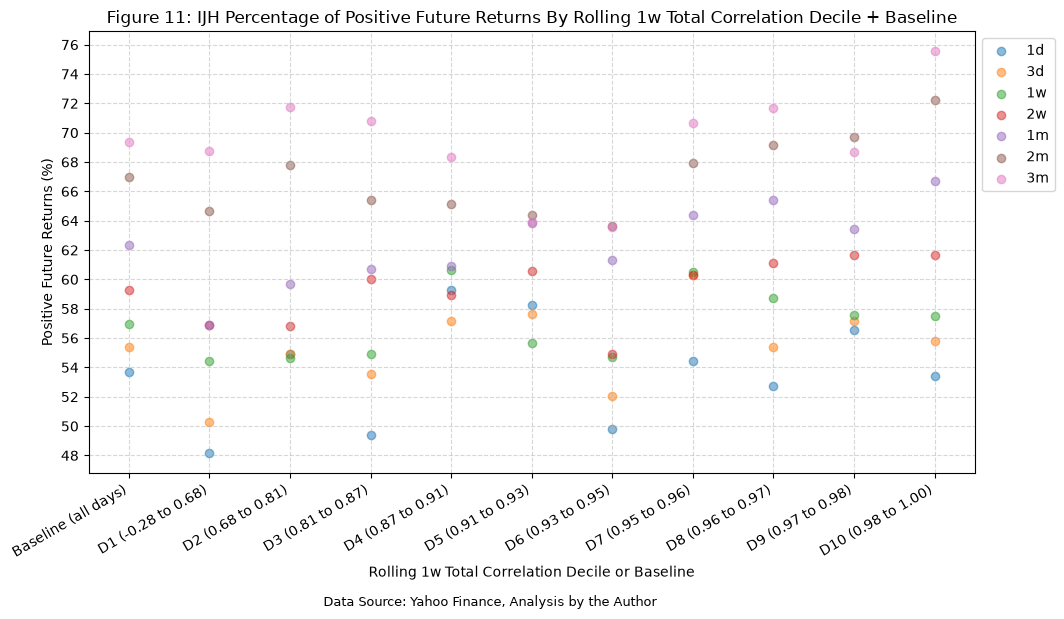

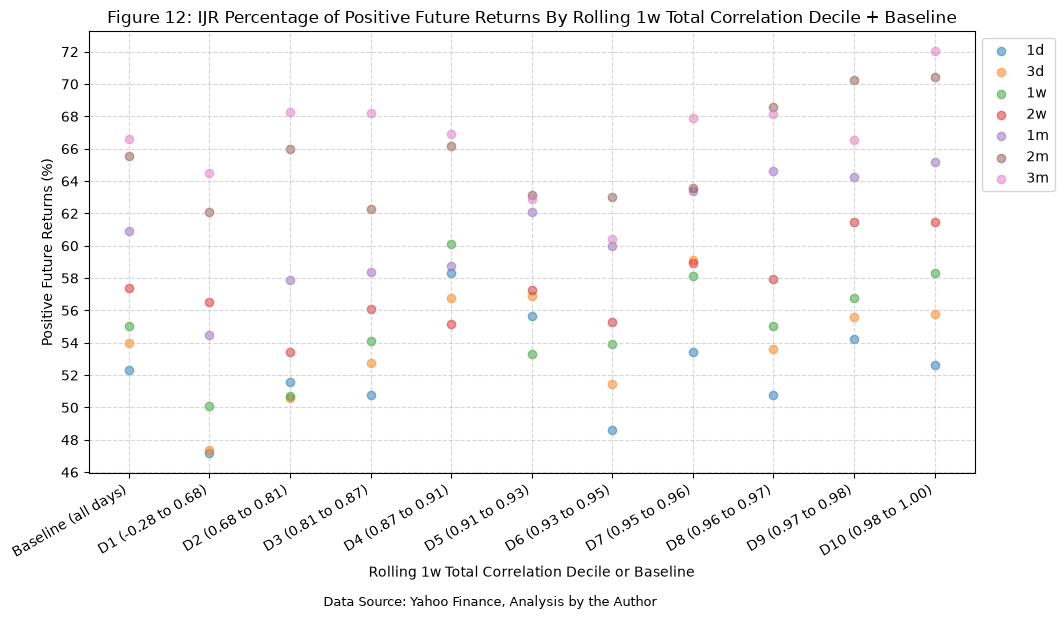

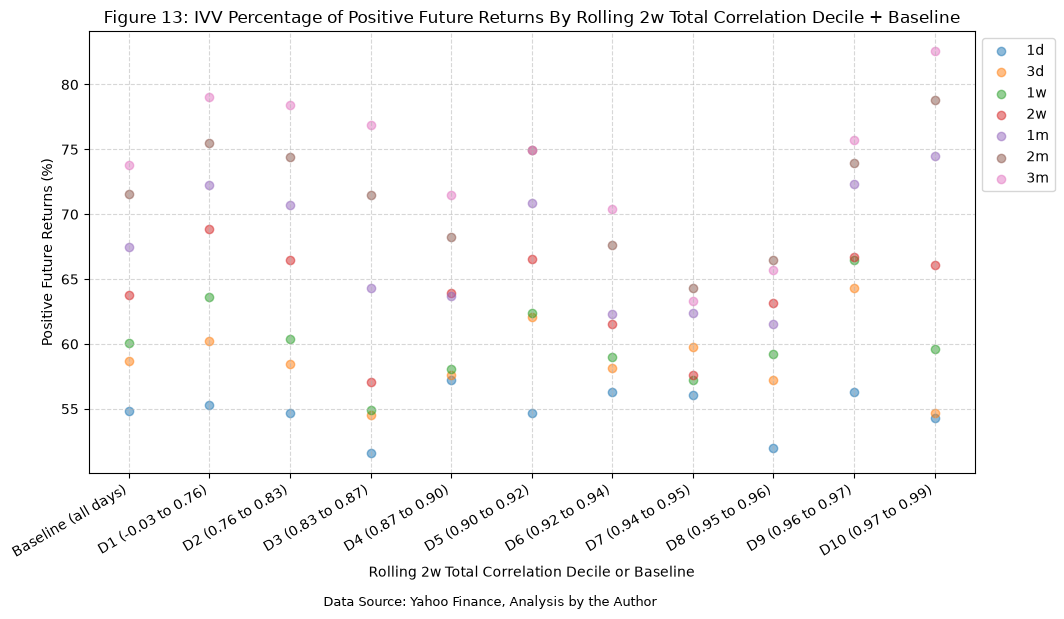

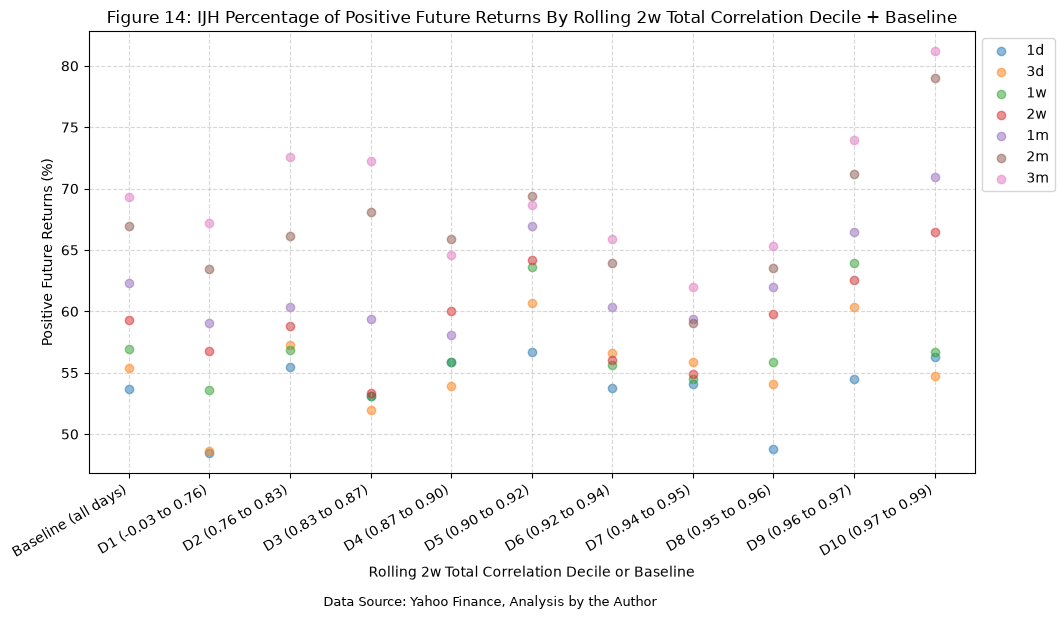

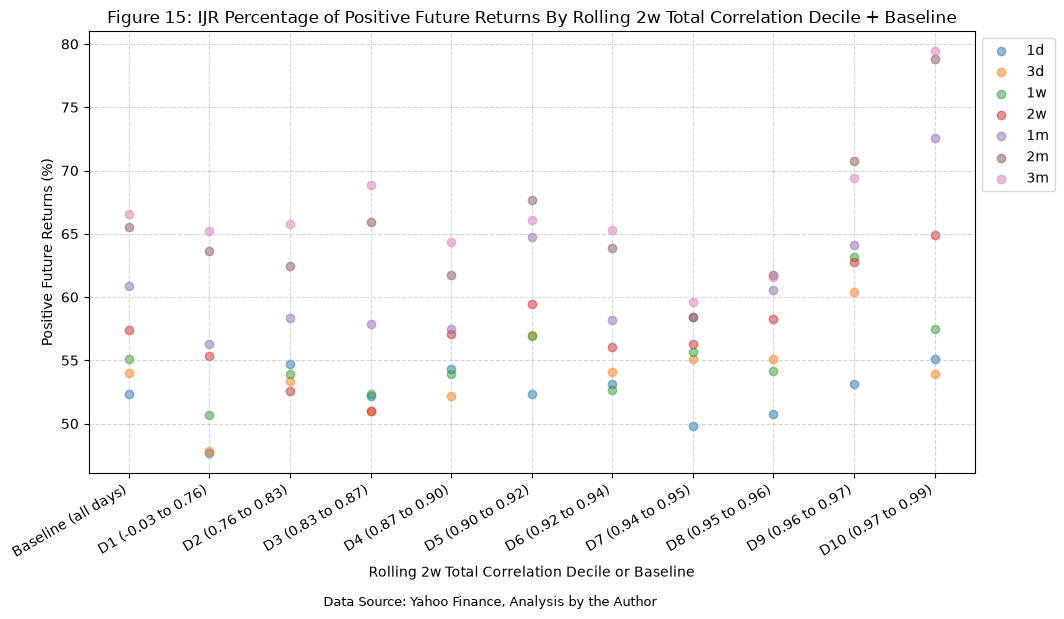

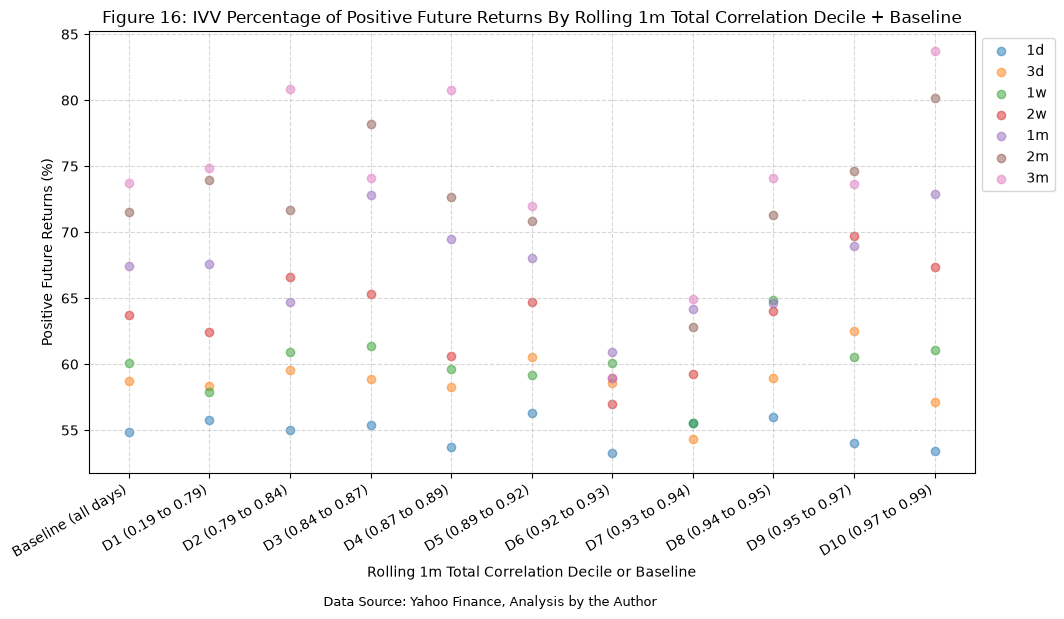

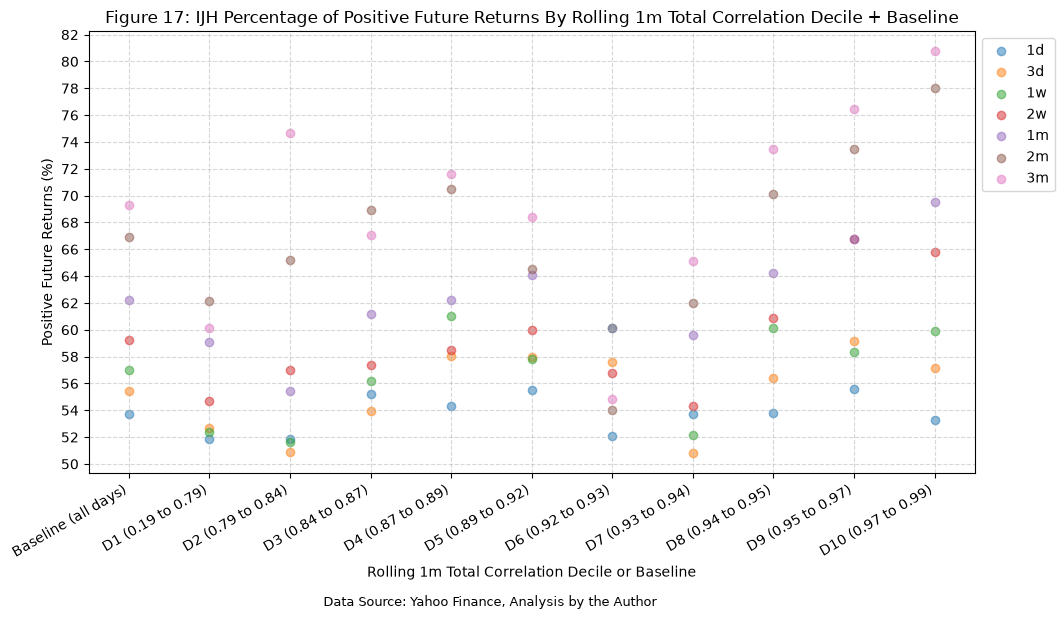

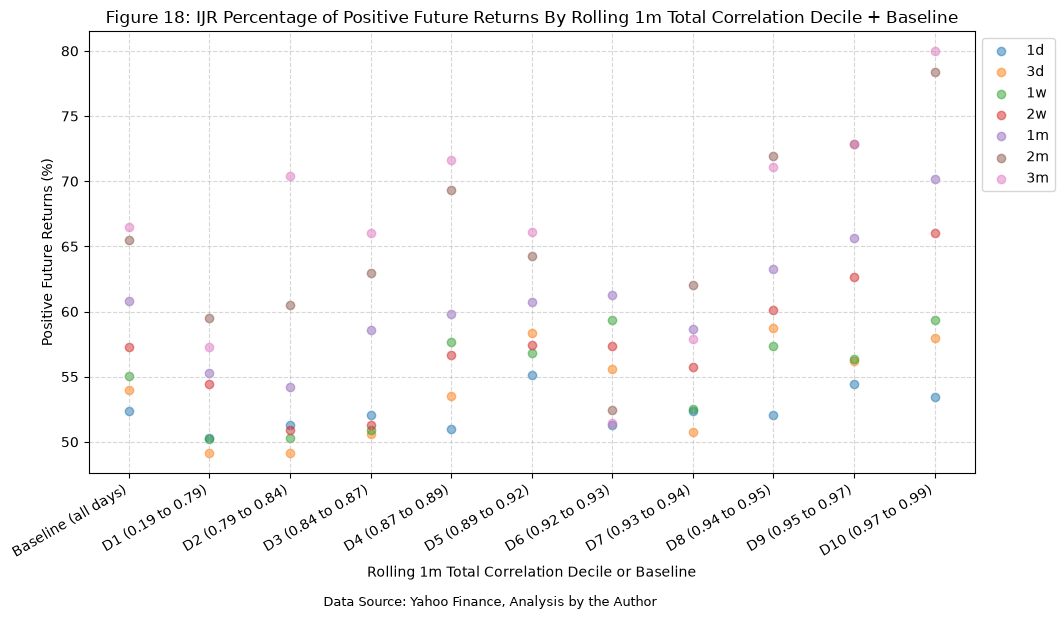

In [17]:
for window in analysis_windows:
    for ticker in tickers:
        # Select this fund's columns (one per return window) and move the decile labels into a column
        ticker_df = (
            decile_summary[window]["pct_positive"]
            .xs(ticker, axis=1, level=1)
            .reset_index(names="Decile")
        )

        plot_scatter(
            df=ticker_df,
            x_plot_column="Decile",
            y_plot_columns=list(return_windows.keys()),
            title=f"Figure {next(figure_number)}: {ticker} Percentage of Positive Future Returns By Rolling {window} Total Correlation Decile + Baseline",
            x_label=f"Rolling {window} Total Correlation Decile or Baseline",
            x_format="String",
            x_format_decimal_places="Auto",
            x_tick_spacing="Auto",
            x_tick_start=None,
            x_tick_rotation=30,
            y_label="Positive Future Returns (%)",
            y_format="Decimal",
            y_format_decimal_places=0,
            y_tick_spacing="Auto",
            y_tick_rotation=0,
            grid=True,
            legend=True,
            legend_location="upper left",
            legend_anchor=(1, 1),
            caption=f"Data Source: Yahoo Finance, Analysis by the Author",
        )

It's interesting what the baseline (all days) columns reveal about future returns. For *every* plot, the positive future return percentage increases as time increases. We see a similar, but slightly less pronounced, trend for the total rolling correlation deciles, and this suggests that, on average, the likelihood of positive future returns grows over longer time horizons, regardless of the rolling correlation decile. There is certainly a "belly" present in some of the plots, particularly at the 6th and 7th deciles.

The 10th decile consistently shows the highest positive future return percentages across all time horizons, indicating that assets in this decile tend to perform better in the future compared to those in lower deciles, so let's cherry pick the 2 week total rolling correlation for IVV, IJH, and IJR, at the 10th decile, and the 3 month forward return to examine more closely.

## 2w Total Rolling Correlation, 10th Decile, 3m Forward Return for IVV, IJH, and IJR

As mentioned above, we will take a closer look at the 2 week total rolling correlation for IVV, IJH, and IJR, at the 10th decile, and the 3 month forward return.

In [18]:
# Assign each day to a correlation decile and record each decile's range
bucket = pd.qcut(total_rolling_corr_with_returns.dropna(subset=["total_rolling_correlation_2w"])["total_rolling_correlation_2w"], 10, labels=decile_labels)

# Merge the decile bucket back into the original DataFrame
total_rolling_corr_with_returns = total_rolling_corr_with_returns.dropna(subset=["total_rolling_correlation_2w"])
total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] = bucket

display(Markdown(f"Table {next(table_number)}: Total Rolling Correlations With 2w Decile Assignments"))
display(total_rolling_corr_with_returns)

Table 10: Total Rolling Correlations With 2w Decile Assignments

,IVV_IJH_3d,IVV_IJH_1w,IVV_IJH_2w,IVV_IJH_1m,IVV_IJH_3m,IVV_IJH_6m,IVV_IJH_1y,IVV_IJH_5y,IVV_IJH_10y,IVV_IJR_3d,...,IJH_Daily_Return_fwd_2m_CRR,IJR_Daily_Return_2m_CRR,IJR_Daily_Return_fwd_2m_CRR,IVV_Daily_Return_3m_CRR,IVV_Daily_Return_fwd_3m_CRR,IJH_Daily_Return_3m_CRR,IJH_Daily_Return_fwd_3m_CRR,IJR_Daily_Return_3m_CRR,IJR_Daily_Return_fwd_3m_CRR,total_rolling_correlation_2w_decile
Date,,,,,,,,,,,,,,,,,,,,,
2006-08-04,0.98,0.98,0.96,NaN,NaN,NaN,NaN,NaN,NaN,0.69,...,0.02,NaN,0.03,NaN,0.07,NaN,0.04,NaN,0.05,D7
2006-08-07,0.79,0.89,0.91,NaN,NaN,NaN,NaN,NaN,NaN,0.97,...,0.04,NaN,0.05,NaN,0.07,NaN,0.05,NaN,0.06,D4
2006-08-08,0.32,0.93,0.92,NaN,NaN,NaN,NaN,NaN,NaN,1.00,...,0.05,NaN,0.06,NaN,0.09,NaN,0.07,NaN,0.09,D5
2006-08-09,-0.01,0.80,0.93,NaN,NaN,NaN,NaN,NaN,NaN,0.74,...,0.06,NaN,0.07,NaN,0.10,NaN,0.09,NaN,0.10,D6
2006-08-10,0.99,0.89,0.95,NaN,NaN,NaN,NaN,NaN,NaN,0.96,...,0.06,NaN,0.07,NaN,0.09,NaN,0.09,NaN,0.10,D6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-04,-0.23,0.58,0.67,0.64,0.70,0.75,0.80,0.88,0.90,0.40,...,NaN,-0.01,NaN,0.00,NaN,-0.03,NaN,-0.03,NaN,D1
2026-11-05,0.99,0.93,0.90,0.88,0.80,0.79,0.81,0.88,0.90,0.99,...,NaN,-0.04,NaN,-0.05,NaN,-0.08,NaN,-0.07,NaN,D5
2026-11-06,0.98,0.93,0.90,0.89,0.80,0.79,0.81,0.88,0.90,1.00,...,NaN,-0.03,NaN,-0.05,NaN,-0.07,NaN,-0.07,NaN,D5


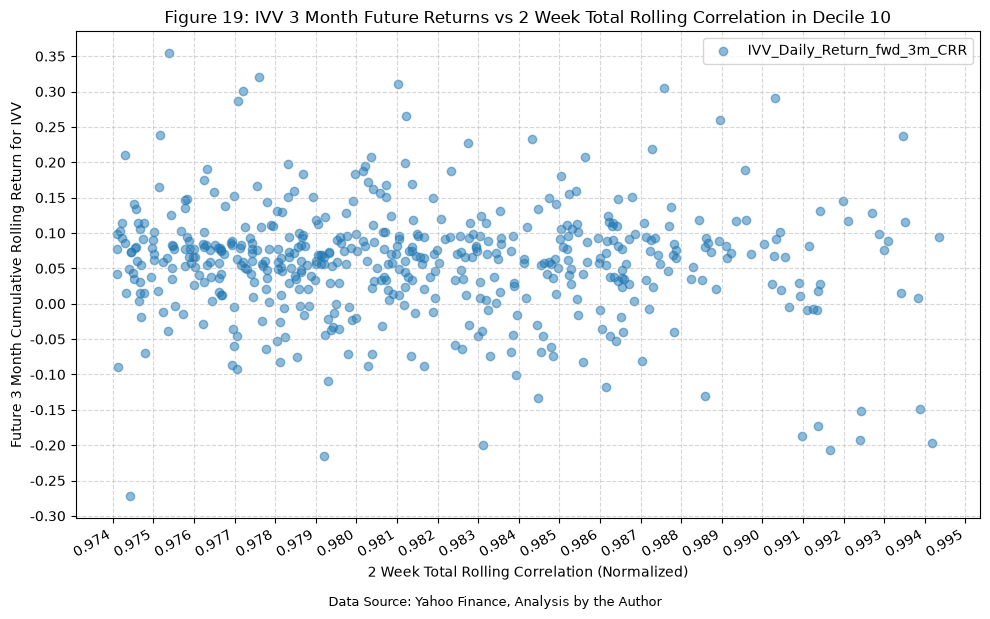

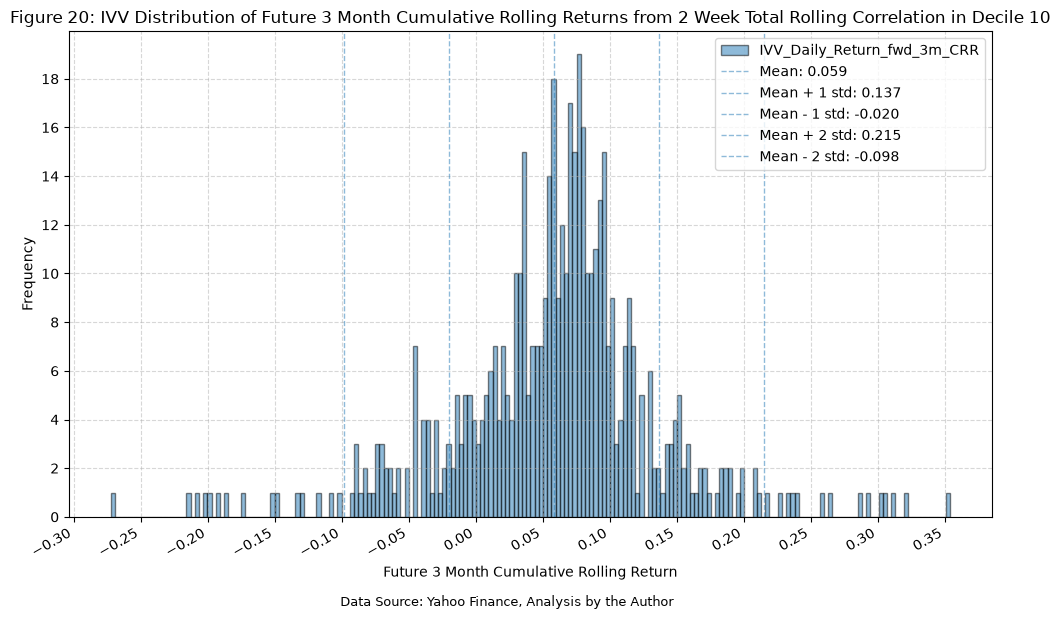

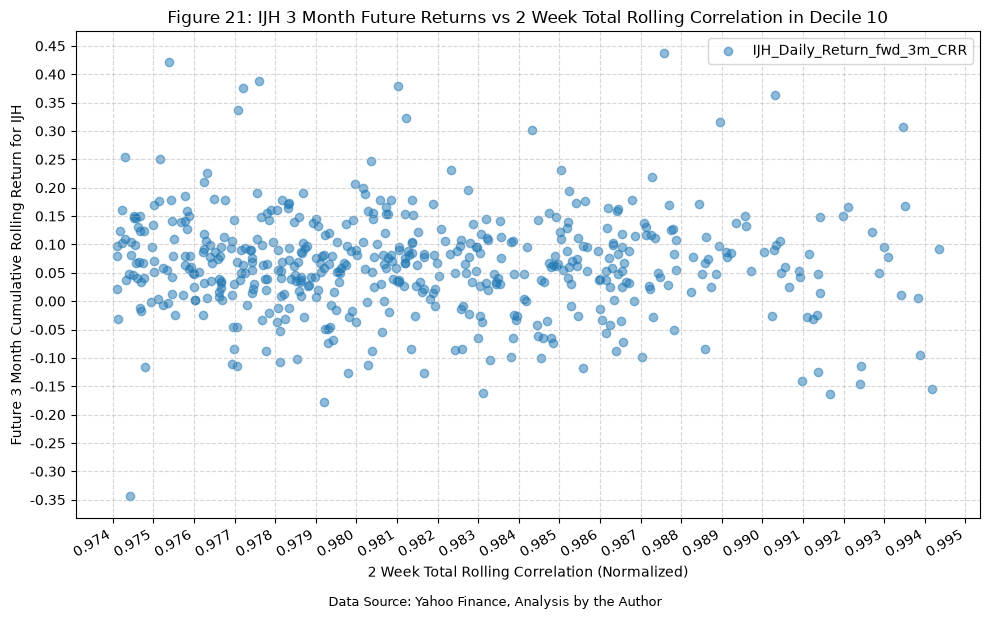

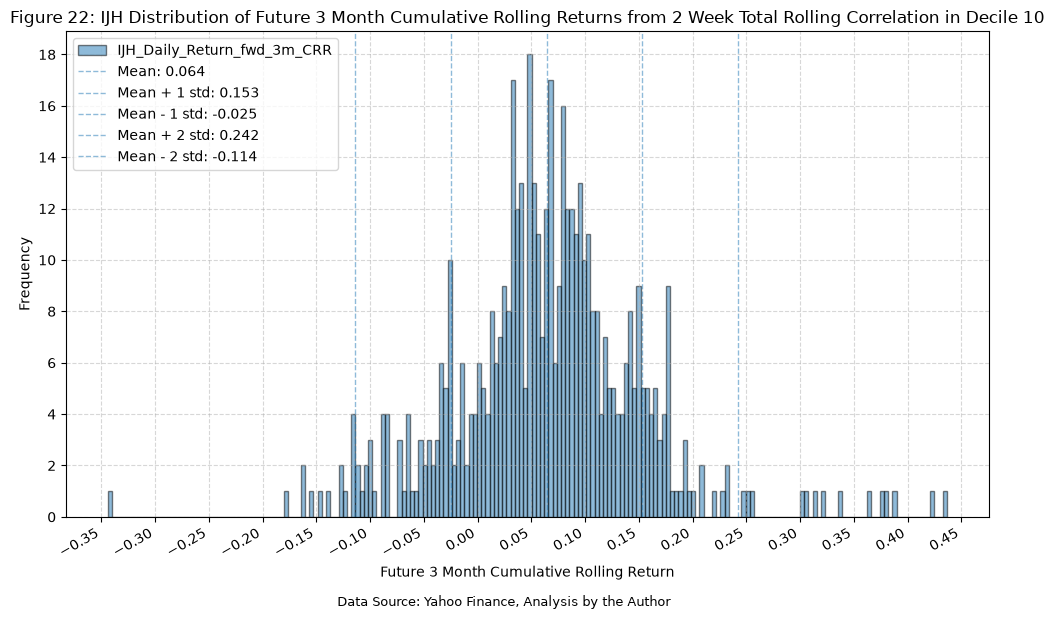

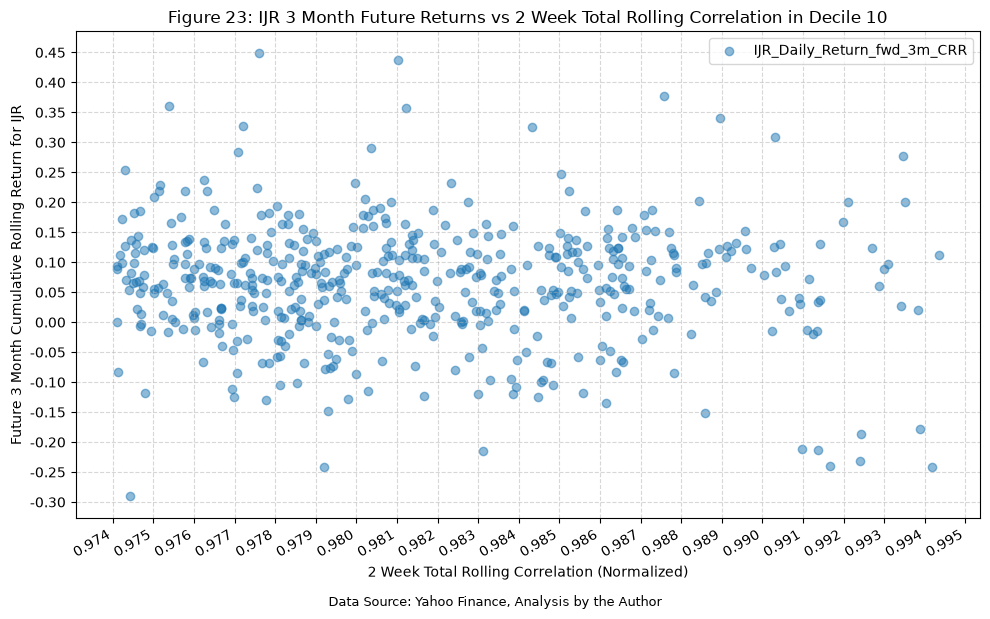

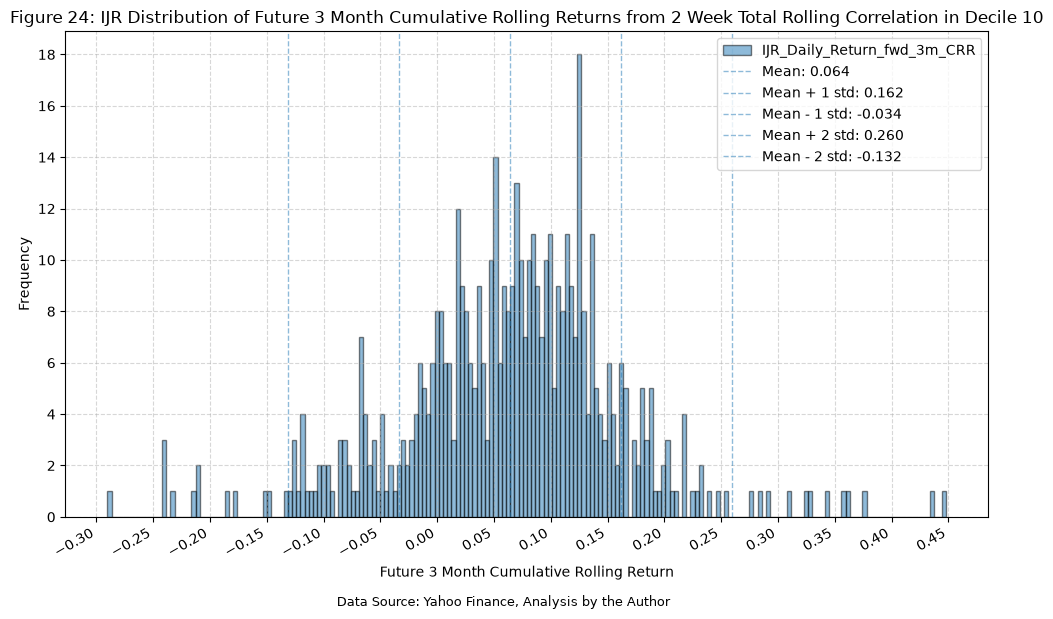

In [19]:
for ticker in tickers:
    plot_scatter(
        df=total_rolling_corr_with_returns[total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] == "D10"],
        x_plot_column="total_rolling_correlation_2w",
        y_plot_columns=[f"{ticker}_Daily_Return_fwd_3m_CRR"],
        title=f"Figure {next(figure_number)}: {ticker} 3 Month Future Returns vs 2 Week Total Rolling Correlation in Decile 10",
        x_label="2 Week Total Rolling Correlation (Normalized)",
        x_format="Decimal",
        x_format_decimal_places="Auto",
        x_tick_spacing="Auto",
        x_tick_start=None,
        x_tick_rotation=30,
        y_label=f"Future 3 Month Cumulative Rolling Return for {ticker}",
        y_format="Decimal",
        y_format_decimal_places=2,
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

    plot_histogram(
        df=total_rolling_corr_with_returns[total_rolling_corr_with_returns["total_rolling_correlation_2w_decile"] == "D10"],
        plot_columns=[f"{ticker}_Daily_Return_fwd_3m_CRR"],
        title=f"Figure {next(figure_number)}: {ticker} Distribution of Future 3 Month Cumulative Rolling Returns from 2 Week Total Rolling Correlation in Decile 10",
        x_label="Future 3 Month Cumulative Rolling Return",
        x_tick_spacing="Auto",
        x_tick_rotation=30,
        y_label="Frequency",
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

With all three of these, we have a mean forward return of 3%, with the -1 standard deviation being around -2/-3%, and the +1 standard deviation being around 13-16%. This shows that while the average expected return is modestly positive, there is a range of potential outcomes.

## Trading Strategy

Next, let's develop a simple trading strategy. When the total rolling correlation hits the 10th decile, we will open a long position in the fund, hold the position for exactly 3 months, and then close it. We'll run the strategy separately for each of six funds: IVV, IJH, and IJR, along with their 2x leveraged counterparts SSO, MVV, and SAA. Here's the complete details:

* Use the 10th decile of the total rolling correlation as the signal for entering a trade.
* Position sizing: we always go fully long on the fund when a signal occurs, and we do not scale in or out.
* Entry: when the 2w total correlation decile is D10 on day i, buy the fund at that day's close.
* Exit: hold for exactly 63 trading days (return_windows["3m"]), then sell at that day's close.
* Overlapping signals: a D10 day that comes while a position is open is ignored. If the exit day is itself a D10 day, the strategy buys again, so the position just continues.
* Shared signal: the signal comes from the total correlation across IVV, IJH, and IJR, so the entry and exit dates are the same for all six funds. Only the returns differ. The leveraged funds are only traded, and do not feed into the signal.
* Inception dates: SAA's return history starts on January 26, 2007, after the first trade closes, so its statistics start from that date and cover 43 trades instead of 44.
* Settings: strategy_tickers, signal_decile and hold_days are variables at the top, so we can easily modify them to try other combinations.

We'll start with the strategy, and the complete list of trades.

In [20]:
# Strategy parameters
strategy_tickers = tickers + leveraged_tickers
signal_column = "total_rolling_correlation_2w_decile"
signal_decile = "D10"
hold_days = return_windows["3m"]  # 63 trading days

# Returns stay NaN before a fund's inception date (SAA starts after the first signals), so that those
# days and trades are left out of that fund's statistics rather than being counted as flat.
strategy_df = total_rolling_corr_with_returns[["total_rolling_correlation_2w", signal_column]].join(
    fund_data[[f"{ticker}_Daily_Return" for ticker in strategy_tickers]]
)
strategy_df["Signal"] = strategy_df[signal_column] == signal_decile

# Walk forward through the days. A signal at the close of day i opens a position at that close,
# which earns the returns of days i+1 through i+hold_days and is then closed. Signals that occur
# while a position is already open are ignored. The signal comes from the total correlation alone,
# so the entry and exit dates are the same for every fund and only the returns differ.
signals = strategy_df["Signal"].to_numpy()
position = np.zeros(len(strategy_df))
trades = []

i = 0
while i < len(strategy_df) - 1:  # A signal on the last day has no following days to trade
    if not signals[i]:
        i += 1
        continue

    entry_idx = i
    exit_idx = min(i + hold_days, len(strategy_df) - 1)
    position[entry_idx + 1 : exit_idx + 1] = 1

    trade = {
        "Entry Date": strategy_df.index[entry_idx],
        "Exit Date": strategy_df.index[exit_idx],
        "Entry Correlation": strategy_df["total_rolling_correlation_2w"].iloc[entry_idx],
        "Days Held": exit_idx - entry_idx,
        "Open": exit_idx - entry_idx < hold_days,  # True if the data ends before the hold period does
    }
    for ticker in strategy_tickers:
        daily_returns = strategy_df[f"{ticker}_Daily_Return"].to_numpy()
        trade[f"{ticker} Return"] = np.prod(1 + daily_returns[entry_idx + 1 : exit_idx + 1]) - 1
    trades.append(trade)

    i = exit_idx

strategy_df["Position"] = position
for ticker in strategy_tickers:
    strategy_df[f"{ticker}_Strategy_Return"] = strategy_df["Position"] * strategy_df[f"{ticker}_Daily_Return"]

display(Markdown(f"Table {next(table_number)}: Days in D10 With an Open Position"))
display(strategy_df[
    (strategy_df["total_rolling_correlation_2w_decile"] == "D10") &
    (strategy_df["Position"] == 1)
])

trades_df = pd.DataFrame(trades)
display(Markdown(f"Table {next(table_number)}: Strategy Trades"))
display(trades_df)

Table 11: Days in D10 With an Open Position

,total_rolling_correlation_2w,total_rolling_correlation_2w_decile,IVV_Daily_Return,IJH_Daily_Return,IJR_Daily_Return,SSO_Daily_Return,MVV_Daily_Return,SAA_Daily_Return,Signal,Position,IVV_Strategy_Return,IJH_Strategy_Return,IJR_Strategy_Return,SSO_Strategy_Return,MVV_Strategy_Return,SAA_Strategy_Return
Date,,,,,,,,,,,,,,,,
2006-08-21,0.98,D10,-0.00,-0.01,-0.01,-0.00,-0.02,NaN,True,1.00,-0.00,-0.01,-0.01,-0.00,-0.02,NaN
2007-02-28,0.98,D10,0.01,0.01,0.01,0.02,0.01,0.01,True,1.00,0.01,0.01,0.01,0.02,0.01,0.01
2007-03-01,0.98,D10,-0.00,-0.00,-0.00,-0.00,-0.01,-0.00,True,1.00,-0.00,-0.00,-0.00,-0.00,-0.01,-0.00
2007-03-02,0.97,D10,-0.01,-0.02,-0.02,-0.03,-0.03,-0.04,True,1.00,-0.01,-0.02,-0.02,-0.03,-0.03,-0.04
2007-03-06,0.97,D10,0.02,0.02,0.02,0.03,0.04,0.05,True,1.00,0.02,0.02,0.02,0.03,0.04,0.05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-04-22,0.99,D10,0.03,0.03,0.02,0.05,0.05,0.05,True,1.00,0.03,0.03,0.02,0.05,0.05,0.05
2025-04-23,0.99,D10,0.02,0.01,0.01,0.03,0.02,0.03,True,1.00,0.02,0.01,0.01,0.03,0.02,0.03
2026-04-09,0.99,D10,0.01,0.00,0.01,0.01,0.00,0.02,True,1.00,0.01,0.00,0.01,0.01,0.00,0.02


Table 12: Strategy Trades

,Entry Date,Exit Date,Entry Correlation,Days Held,Open,IVV Return,IJH Return,IJR Return,SSO Return,MVV Return,SAA Return
0,2006-08-17,2006-11-15,0.98,63,False,0.08,0.08,0.10,0.15,0.15,NaN
1,2007-02-27,2007-05-29,0.98,63,False,0.10,0.09,0.08,0.18,0.15,0.15
2,2007-06-14,2007-09-13,0.98,63,False,-0.02,-0.05,-0.05,-0.07,-0.12,-0.12
3,2007-09-27,2007-12-27,0.98,63,False,-0.03,-0.03,-0.07,-0.08,-0.07,-0.15
4,2008-03-07,2008-06-06,0.98,63,False,0.06,0.15,0.11,0.09,0.30,0.21
5,2008-06-06,2008-09-05,0.99,63,False,-0.08,-0.10,-0.03,-0.17,-0.21,-0.08
6,2008-11-14,2009-02-18,0.97,63,False,-0.09,-0.03,-0.08,-0.22,-0.14,-0.23
7,2009-02-24,2009-05-26,0.98,63,False,0.19,0.23,0.23,0.36,0.43,0.43
8,2009-05-27,2009-08-25,0.98,63,False,0.16,0.18,0.19,0.32,0.37,0.39
9,2009-08-25,2009-11-23,0.99,63,False,0.08,0.05,0.03,0.16,0.10,0.04


Next, here's the statistics for win rate, average return, max gain, and max loss.

In [21]:
# Trade summary
closed_trades = trades_df[~trades_df["Open"]]

print(f"Total trades: {len(trades_df)} ({len(closed_trades)} closed)")
print(f"Time in market: {strategy_df['Position'].mean() * 100:.2f}%")

for ticker in strategy_tickers:
    trade_returns = closed_trades[f"{ticker} Return"].dropna()
    print(f"\n{ticker}:")
    print(f"  Closed trades: {len(trade_returns)}")
    print(f"  Win rate (closed trades): {(trade_returns > 0).mean() * 100:.2f}%")
    print(f"  Average return per closed trade: {trade_returns.mean() * 100:.2f}%")
    print(f"  Max trade gain: {trade_returns.max() * 100:.2f}%")
    print(f"  Max trade loss: {trade_returns.min() * 100:.2f}%")

Total trades: 44 (44 closed)
Time in market: 54.36%

IVV:
  Closed trades: 44
  Win rate (closed trades): 68.18%
  Average return per closed trade: 3.96%
  Max trade gain: 18.70%
  Max trade loss: -9.01%

IJH:
  Closed trades: 44
  Win rate (closed trades): 68.18%
  Average return per closed trade: 4.37%
  Max trade gain: 23.09%
  Max trade loss: -11.54%

IJR:
  Closed trades: 44
  Win rate (closed trades): 65.91%
  Average return per closed trade: 4.32%
  Max trade gain: 23.17%
  Max trade loss: -11.87%

SSO:
  Closed trades: 44
  Win rate (closed trades): 63.64%
  Average return per closed trade: 6.60%
  Max trade gain: 35.67%
  Max trade loss: -21.76%

MVV:
  Closed trades: 44
  Win rate (closed trades): 63.64%
  Average return per closed trade: 7.14%
  Max trade gain: 43.41%
  Max trade loss: -22.68%

SAA:
  Closed trades: 43
  Win rate (closed trades): 60.47%
  Average return per closed trade: 6.75%
  Max trade gain: 43.02%
  Max trade loss: -25.61%


Now we can compare the summary stats for the different funds and see how the strategy performed across all six funds.

In [22]:
# Compare each strategy against buy and hold for the same period
strategy_stats = pd.concat(
    [
        summary_stats(
            fund_list=[ticker],
            df=strategy_df[[return_column]].dropna(),
            period="Daily",
            use_calendar_days=False,
            excel_export=False,
            pickle_export=False,
            output_confirmation=False,
        )
        for ticker in strategy_tickers
        for return_column in [f"{ticker}_Strategy_Return", f"{ticker}_Daily_Return"]
    ]
)

display(Markdown(f"Table {next(table_number)}: Strategy vs Buy and Hold Summary Statistics"))
display(strategy_stats)

Table 13: Strategy vs Buy and Hold Summary Statistics

,Number of Observations,Data Start Date,Data End Date,Annual Mean Return (Arithmetic),Annualized Volatility,Annualized Sharpe Ratio,CAGR (Geometric),Daily Max Return,Daily Max Return (Date),Daily Min Return,Daily Min Return (Date),Max Drawdown,Peak,Trough,Recovery Date,Calendar Days to Recovery,MAR Ratio
IVV_Strategy_Return,5099,2006-08-04,2026-11-10,0.09,0.15,0.59,0.08,0.10,2025-04-09,-0.12,2020-03-16,-0.30,2008-05-19,2009-03-09,2009-06-01,84.00,0.28
IVV_Daily_Return,5099,2006-08-04,2026-11-10,0.12,0.19,0.65,0.11,0.11,2008-10-28,-0.12,2020-03-16,-0.55,2007-10-09,2009-03-09,2012-08-16,1256.00,0.20
IJH_Strategy_Return,5099,2006-08-04,2026-11-10,0.10,0.18,0.58,0.09,0.11,2020-03-24,-0.14,2020-03-16,-0.36,2019-11-08,2020-03-23,2020-06-30,99.00,0.25
IJH_Daily_Return,5099,2006-08-04,2026-11-10,0.12,0.22,0.54,0.10,0.11,2020-03-24,-0.14,2020-03-16,-0.55,2007-06-04,2009-03-09,2010-12-02,633.00,0.18
IJR_Strategy_Return,5099,2006-08-04,2026-11-10,0.10,0.19,0.54,0.09,0.09,2025-04-09,-0.12,2020-03-16,-0.35,2019-11-05,2020-03-23,2020-07-21,120.00,0.25
IJR_Daily_Return,5099,2006-08-04,2026-11-10,0.12,0.24,0.50,0.09,0.09,2025-04-09,-0.12,2020-03-16,-0.58,2007-07-19,2009-03-09,2011-02-07,700.00,0.16
SSO_Strategy_Return,5099,2006-08-04,2026-11-10,0.17,0.31,0.54,0.13,0.19,2020-03-24,-0.23,2020-03-16,-0.55,2007-07-13,2009-03-09,2009-08-07,151.00,0.23
SSO_Daily_Return,5099,2006-08-04,2026-11-10,0.21,0.38,0.56,0.15,0.22,2008-10-13,-0.23,2020-03-16,-0.85,2007-10-09,2009-03-09,2013-10-22,1688.00,0.18
MVV_Strategy_Return,5099,2006-08-04,2026-11-10,0.19,0.36,0.53,0.13,0.20,2025-04-09,-0.29,2020-03-16,-0.62,2019-11-05,2020-03-23,2020-08-05,135.00,0.21
MVV_Daily_Return,5099,2006-08-04,2026-11-10,0.20,0.44,0.46,0.11,0.25,2008-10-13,-0.29,2020-03-16,-0.86,2007-06-04,2009-03-09,2013-04-30,1513.00,0.13


And finally, the plots for the cumulative returns and drawdowns.

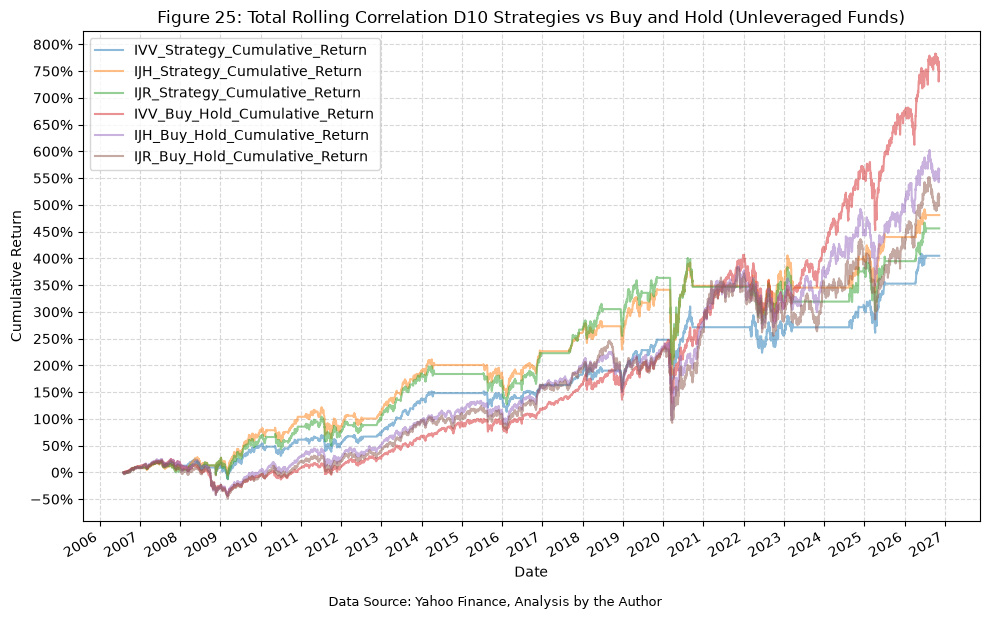

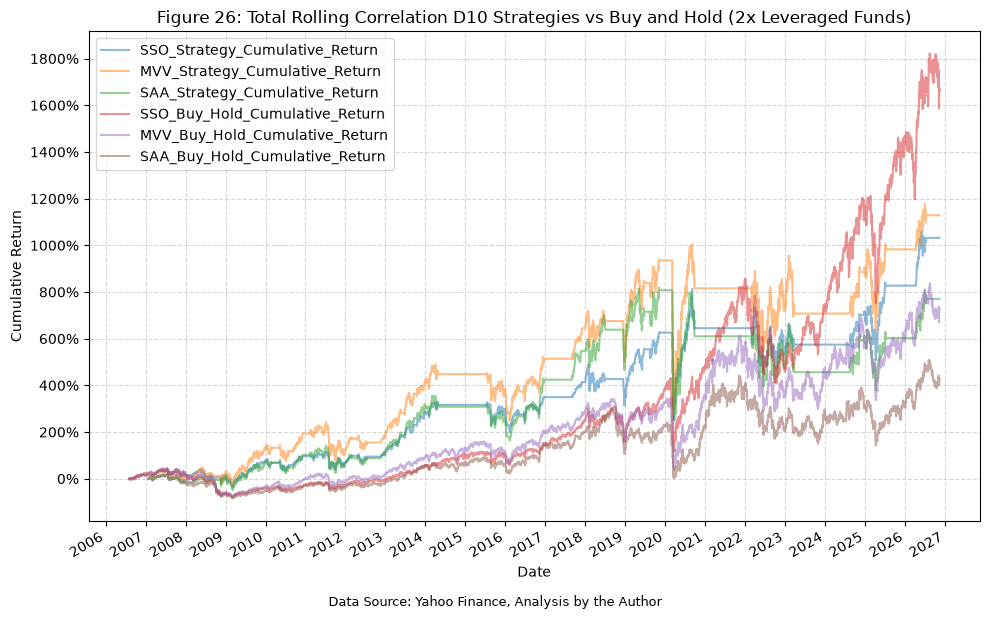

In [23]:
# Cumulative returns for each strategy and buy and hold
for ticker in strategy_tickers:
    strategy_df[f"{ticker}_Strategy_Cumulative_Return"] = (1 + strategy_df[f"{ticker}_Strategy_Return"]).cumprod() - 1
    strategy_df[f"{ticker}_Buy_Hold_Cumulative_Return"] = (1 + strategy_df[f"{ticker}_Daily_Return"]).cumprod() - 1

for fund_group, group_tickers in {"Unleveraged": tickers, "2x Leveraged": leveraged_tickers}.items():
    plot_time_series(
        df=strategy_df,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[f"{ticker}_Strategy_Cumulative_Return" for ticker in group_tickers]
        + [f"{ticker}_Buy_Hold_Cumulative_Return" for ticker in group_tickers],
        title=f"Figure {next(figure_number)}: Total Rolling Correlation {signal_decile} Strategies vs Buy and Hold ({fund_group} Funds)",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Cumulative Return",
        y_format="Percentage",
        y_format_decimal_places=0,
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

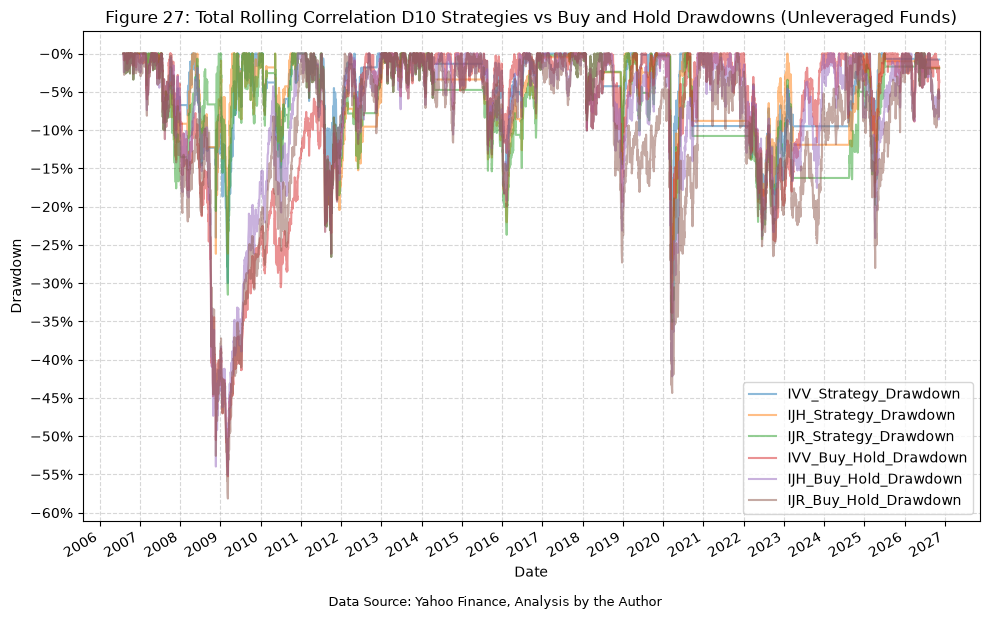

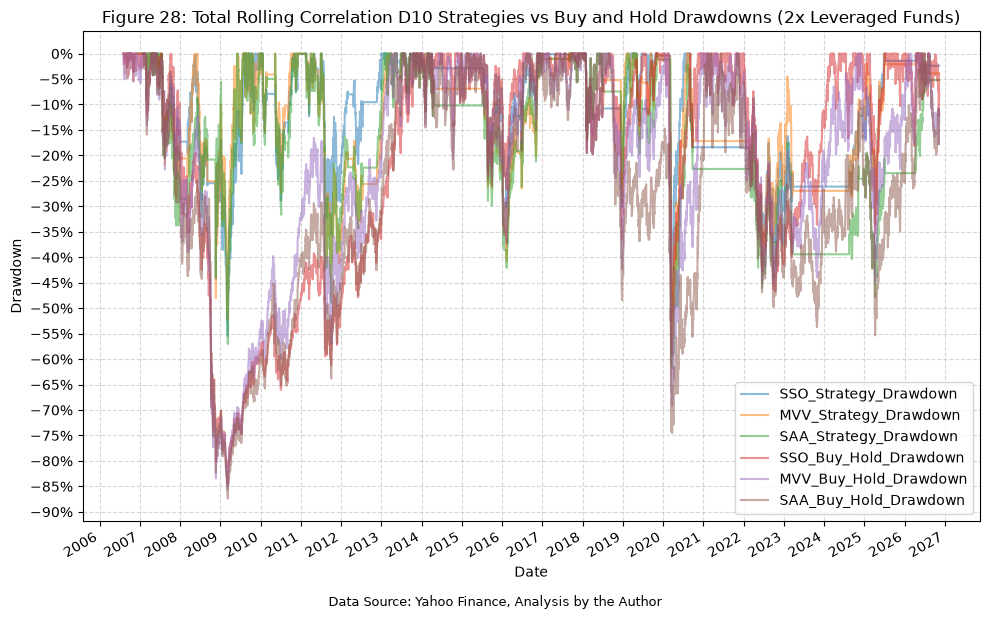

In [24]:
# Drawdowns for each strategy and buy and hold, measured from the running peak of each equity curve
for ticker in strategy_tickers:
    strategy_equity = (1 + strategy_df[f"{ticker}_Strategy_Return"]).cumprod()
    buy_hold_equity = (1 + strategy_df[f"{ticker}_Daily_Return"]).cumprod()

    strategy_df[f"{ticker}_Strategy_Drawdown"] = strategy_equity / strategy_equity.cummax() - 1
    strategy_df[f"{ticker}_Buy_Hold_Drawdown"] = buy_hold_equity / buy_hold_equity.cummax() - 1

for fund_group, group_tickers in {"Unleveraged": tickers, "2x Leveraged": leveraged_tickers}.items():
    plot_time_series(
        df=strategy_df,
        plot_start_date=None,
        plot_end_date=None,
        plot_columns=[f"{ticker}_Strategy_Drawdown" for ticker in group_tickers]
        + [f"{ticker}_Buy_Hold_Drawdown" for ticker in group_tickers],
        title=f"Figure {next(figure_number)}: Total Rolling Correlation {signal_decile} Strategies vs Buy and Hold Drawdowns ({fund_group} Funds)",
        x_label="Date",
        x_format="Year",
        x_tick_spacing=1,
        x_tick_start=None,
        x_tick_rotation=30,
        y_label="Drawdown",
        y_format="Percentage",
        y_format_decimal_places=0,
        y_tick_spacing="Auto",
        y_tick_rotation=0,
        grid=True,
        legend=True,
        export_plot=False,
        plot_file_name=None,
        caption=f"Data Source: Yahoo Finance, Analysis by the Author",
    )

Starting with the unleveraged funds, we end up with 44 trades over the 20 year period, with a win rate of 68% for IVV and IJH, and 66% for IJR, not bad overall. Since the signal is shared, all three strategies spend just under 55% of their time in the market, which really gives us an opportunity to use our capital the other 45% of the time, either in a risk free asset or another strategy altogether.

For IVV, with a CAGR of 8%, we underperform the buy-and-hold strategy over the same period, but we also experience lower volatility (15% vs 19%), and much lower max drawdowns (30% vs 55%). Our strategy gives us a MAR ratio of 0.28, vs 0.20 for the buy-and-hold strategy.

IJH and IJR tell a similar story, but the gap in CAGR is much smaller:

* IJH: a CAGR of 9.1% vs 9.8% for buy-and-hold, with lower volatility (18% vs 22%), lower max drawdowns (36% vs 55%), and a MAR ratio of 0.25 vs 0.18.
* IJR: a CAGR of 8.9% vs 9.4% for buy-and-hold, with lower volatility (19% vs 24%), lower max drawdowns (35% vs 58%), and a MAR ratio of 0.25 vs 0.16.

For IJH and IJR, we give up less than 1% of CAGR per year in exchange for the reduced risk, and both strategies also have a higher Sharpe ratio than their buy-and-hold counterparts, which is not the case for IVV.

The difference in CAGR does add up over the long term, the effect of which we can see in the cumulative return plot, particularly for IVV.

The drawdown plot further illustrates the reduced risk of the strategies compared to the buy-and-hold approach, highlighting the lower maximum drawdowns experienced over the same period. During the GFC, the IVV strategy experienced its max drawdown of 30%, which was significantly lower than that of the buy-and-hold strategy at 55%. Interestingly, the max drawdowns for the IJH and IJR strategies came during the COVID crash in early 2020 rather than the GFC, while all three buy-and-hold strategies saw their max drawdowns during the GFC.

Moving on to the 2x leveraged funds, the win rates are lower (64% for SSO and MVV, and 60% for SAA over its 43 trades), but the results relative to buy-and-hold are more interesting:

* SSO: a CAGR of 12.8% vs 15.6% for buy-and-hold, with lower volatility (31% vs 38%), lower max drawdowns (55% vs 85%), and a MAR ratio of 0.23 vs 0.18.
* MVV: a CAGR of 13.2% vs 11.0% for buy-and-hold, with lower volatility (36% vs 44%), lower max drawdowns (62% vs 86%), and a MAR ratio of 0.21 vs 0.13.
* SAA: a CAGR of 11.6% vs 8.9% for buy-and-hold, with lower volatility (38% vs 48%), lower max drawdowns (61% vs 87%), and a MAR ratio of 0.19 vs 0.10.

For MVV and SAA, the strategy beats buy-and-hold on CAGR, despite being out of the market about 45% of the time. As with IVV, SSO gives up CAGR and has a slightly lower Sharpe ratio than buy-and-hold, while MVV and SAA have higher Sharpe ratios. Even with the strategy, the leveraged funds still see max drawdowns of more than 50%, so the reduced risk is relative. The max drawdown for the SSO strategy came during the GFC, and for the MVV and SAA strategies it came during the COVID crash, matching the pattern we see with the unleveraged funds.

## Conclusion

Overall, we delved into the different deciles of a "total correlation" metric, assembled from the rolling correlations of 3 well known US equity ETFs. This analysis, including comparison to a baseline, gave us insight into where the total correlations could be used to improve our ability to time market entries and exits. Finally, we built a simple trading strategy using a single total correlation window and decile and a single future return window, as a proof of concept for how these insights could be applied in practice. This strategy, while underperforming buy-and-hold over the long-term for IVV, IJH, IJR, and SSO, did have lower volatility and drawdowns for all six funds, and outperformed buy-and-hold for MVV and SAA, demonstrating the potential risk management benefits of incorporating total correlation information into trading decisions.

## Future Investigation

None

## References

None